In [ ]:
# Install wfdb if not already installed
!pip install wfdb antropy

import wfdb
import numpy as np
import pandas as pd
import antropy as ant
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import os
import glob
import re
import warnings
warnings.filterwarnings("ignore")

from scipy import signal as sp_signal
from scipy.fft import fft, fftfreq
from scipy.stats import pearsonr

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, ConfusionMatrixDisplay)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTETomek # Corrected typo: imbleblearn to imblearn
from collections import Counter

print("✅ All libraries imported successfully")

✅ All libraries imported successfully


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_DIR = '/content/drive/MyDrive/Colab Notebooks/term-preterm-ehg-database-1.0.1/tpehgdb/'

WAVELET = 'db4'
LEVEL   = 3
MODE    = 'soft'

assert os.path.isdir(DATA_DIR), f"Folder not found: {DATA_DIR}"

dat_files = sorted(glob.glob(os.path.join(DATA_DIR, '*.dat')))
hea_files = sorted(glob.glob(os.path.join(DATA_DIR, '*.hea')))

print(f"\n📂 Drive folder  : {DATA_DIR}")
print(f"   .dat files    : {len(dat_files)}")
print(f"   .hea files    : {len(hea_files)}")


📂 Drive folder  : /content/drive/MyDrive/Colab Notebooks/term-preterm-ehg-database-1.0.1/tpehgdb/
   .dat files    : 300
   .hea files    : 300


In [ ]:
def parse_hea(hea_path):
    record_id = os.path.splitext(os.path.basename(hea_path))[0]
    fields    = {"record_id": record_id}

    field_map = {
        "Gestation": "gestation",
        "Rectime": "rectime",
        "Age": "age",
        "Parity": "parity",
        "Abortions": "abortions",
        "Weight": "weight",
        "Hypertension": "hypertension",
        "Diabetes": "diabetes",
        "Placental_position": "placental_position",
        "Bleeding_first_trimester": "bleeding_1st",
        "Bleeding_second_trimester": "bleeding_2nd",
        "Funneling": "funneling",
        "Smoker": "smoker",
    }

    with open(hea_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line.startswith("#"):
                continue
            content = line.lstrip("#").strip()
            parts   = content.split(None, 1)
            if len(parts) < 2:
                continue
            key, val = parts[0], parts[1].strip()
            if key in field_map:
                fields[field_map[key]] = val

    return fields

In [ ]:
meta_rows = [parse_hea(f) for f in hea_files]
meta_df   = pd.DataFrame(meta_rows)

for col in ["gestation", "rectime", "age", "parity", "abortions", "weight"]:
    meta_df[col] = pd.to_numeric(meta_df[col], errors="coerce")

meta_df["label"] = (meta_df["gestation"] < 37).astype(int)

print(f"\nMetadata shape : {meta_df.shape}")
print(f"\nLabel distribution:\n{meta_df['label'].value_counts()}")

META_CSV = os.path.join(DATA_DIR, "tpehg_metadata.csv")
meta_df.to_csv(META_CSV, index=False)

print(f"\n✅ Metadata CSV saved: {META_CSV}")


Metadata shape : (300, 15)

Label distribution:
label
0    262
1     38
Name: count, dtype: int64

✅ Metadata CSV saved: /content/drive/MyDrive/Colab Notebooks/term-preterm-ehg-database-1.0.1/tpehgdb/tpehg_metadata.csv


In [ ]:
import pywt

def wavelet_denoise(sig):
    sig    = np.nan_to_num(sig.astype(np.float64))
    coeffs = pywt.wavedec(sig, wavelet=WAVELET, level=LEVEL)
    sigma  = np.median(np.abs(coeffs[-1])) / 0.6745
    thresh = sigma * np.sqrt(2 * np.log(len(sig)))
    coeffs_t = [coeffs[0]] + [
        pywt.threshold(c, value=thresh, mode=MODE) for c in coeffs[1:]
    ]
    return pywt.waverec(coeffs_t, wavelet=WAVELET)[:len(sig)]

def bandpass_filter(sig, fs=20, low=0.3, high=3.0):
    nyq  = fs / 2
    b, a = sp_signal.butter(4, [low / nyq, high / nyq], btype='band')
    return sp_signal.filtfilt(b, a, sig)

def remove_artifacts(sig, threshold=5.0):
    med = np.median(sig)
    std = np.std(sig)
    sig_c = sig.copy()
    sig_c[np.abs(sig - med) > threshold * std] = med
    return sig_c

In [ ]:
def time_features(sig, ch):
    return {
        f"{ch}_rms": np.sqrt(np.mean(sig**2)),
        f"{ch}_std": np.std(sig),
        f"{ch}_mean": np.mean(sig),
        f"{ch}_mean_abs": np.mean(np.abs(sig)),
        f"{ch}_variance": np.var(sig),
        f"{ch}_zcr": np.sum(np.diff(np.sign(sig)) != 0) / len(sig),
        f"{ch}_waveform_len": np.sum(np.abs(np.diff(sig))),
        f"{ch}_log_detector": np.exp(np.mean(np.log(np.abs(sig) + 1e-10))),
        f"{ch}_ptp": np.ptp(sig),
    }

def freq_features(sig, fs=20, ch="ch"):
    N = len(sig)
    freqs = fftfreq(N, d=1/fs)[:N//2]
    psd = (2.0 / N * np.abs(fft(sig)[:N//2]))**2
    total = np.sum(psd) + 1e-10
    cum = np.cumsum(psd)
    low_p = np.sum(psd[freqs < 1.0])
    hig_p = np.sum(psd[freqs >= 1.0])
    return {
        f"{ch}_median_freq": float(freqs[np.searchsorted(cum, total * 0.5)]),
        f"{ch}_mean_freq": float(np.sum(freqs * psd) / total),
        f"{ch}_peak_freq": float(freqs[np.argmax(psd)]),
        f"{ch}_spectral_energy": float(total),
        f"{ch}_hl_freq_ratio": float(hig_p / (low_p + 1e-10)),
    }

def entropy_features(sig, ch):
    try: se = ant.sample_entropy(sig)
    except: se = np.nan
    try: ae = ant.app_entropy(sig)
    except: ae = np.nan
    try: pe = ant.perm_entropy(sig, normalize=True)
    except: pe = np.nan
    return {
        f"{ch}_sample_entropy": se,
        f"{ch}_approx_entropy": ae,
        f"{ch}_perm_entropy": pe,
    }

def nonlinear_features(sig, ch):
    act = np.var(sig)
    d1  = np.diff(sig)
    d2  = np.diff(d1)
    mob = np.sqrt(np.var(d1) / (act + 1e-10))
    cmp = np.sqrt(np.var(d2) / (np.var(d1) + 1e-10)) / (mob + 1e-10)
    try: hfd = ant.higuchi_fd(sig)
    except: hfd = np.nan
    return {
        f"{ch}_hjorth_activity": float(act),
        f"{ch}_hjorth_mobility": float(mob),
        f"{ch}_hjorth_complexity": float(cmp),
        f"{ch}_higuchi_fd": float(hfd),
    }

In [ ]:
def extract_record_features(sig_array, fs=20):
    row = {}
    for i in range(sig_array.shape[1]):
        ch = f"ch{i+1}"
        sig = sig_array[:, i]
        sig = sig[~np.isnan(sig)]
        if len(sig) == 0:
            continue

        sig = wavelet_denoise(sig)
        sig = remove_artifacts(sig)
        sig_filt = bandpass_filter(sig, fs)

        row.update(time_features(sig_filt, ch))
        row.update(freq_features(sig_filt, fs, ch))
        row.update(entropy_features(sig_filt, ch))
        row.update(nonlinear_features(sig_filt, ch))

    return row

In [ ]:
# ============================================================
# STEP 4 — OPTIMIZED FEATURE EXTRACTION
# Fixes: entropy downsampling + parallel + checkpoint
# ============================================================
from joblib import Parallel, delayed
import time

FS              = 20
CHECKPOINT_CSV  = os.path.join(DATA_DIR, "tpehg_features_checkpoint.csv")
ENTROPY_SAMPLES = 1000  # downsample before entropy (O(n²) → 900x faster)
N_JOBS          = 2     # Colab T4 = 2 vCPUs

print("\n" + "="*60)
print("STEP 4 — FEATURE EXTRACTION FROM RAW SIGNALS (OPTIMIZED)")
print("="*60)

# ── Optimized extractor ───────────────────────────────────────
def extract_record_features(sig_array, fs=20):
    row = {}
    for i in range(sig_array.shape[1]):
        ch  = f"ch{i+1}"
        sig = sig_array[:, i]
        sig = sig[~np.isnan(sig)]
        if len(sig) == 0:
            continue
        sig      = wavelet_denoise(sig)
        sig      = remove_artifacts(sig)
        sig_filt = bandpass_filter(sig, fs)

        # Full signal → time, freq, nonlinear
        row.update(time_features(sig_filt, ch))
        row.update(freq_features(sig_filt, fs, ch))
        row.update(nonlinear_features(sig_filt, ch))

        # ✅ Downsample before entropy — sample_entropy is O(n²)
        # 30k samples = 900M ops | 1k samples = 1M ops → 900x faster
        step     = max(1, len(sig_filt) // ENTROPY_SAMPLES)
        sig_down = sig_filt[::step][:ENTROPY_SAMPLES]
        row.update(entropy_features(sig_down, ch))
    return row

# ── Worker for one record ─────────────────────────────────────
def process_one(row_tuple):
    i, row = row_tuple
    rec_id   = row["record_id"]
    rec_path = os.path.join(DATA_DIR, rec_id)
    try:
        rec   = wfdb.rdrecord(rec_path)
        feats = extract_record_features(rec.p_signal, fs=FS)
        feats["record_id"] = rec_id
        feats["label"]     = row["label"]
        for col in ["age","parity","abortions","weight",
                    "hypertension","diabetes","placental_position",
                    "bleeding_1st","bleeding_2nd","funneling","smoker"]:
            feats[col] = row.get(col, np.nan)
        return feats, rec_id, None
    except Exception as e:
        return None, rec_id, str(e)

# ── Resume from checkpoint if exists ─────────────────────────
if os.path.exists(CHECKPOINT_CSV):
    done_df  = pd.read_csv(CHECKPOINT_CSV)
    done_ids = set(done_df["record_id"].tolist())
    all_rows = done_df.to_dict("records")
    print(f"♻️  Resuming: {len(done_ids)} records already done")
else:
    done_ids = set()
    all_rows = []
    print("🆕 Starting fresh")

pending = [(i, row) for i, row in meta_df.iterrows()
           if row["record_id"] not in done_ids]

print(f"📋 Pending : {len(pending)} | Done : {len(done_ids)}")
print(f"⚙️  n_jobs={N_JOBS} | entropy_samples={ENTROPY_SAMPLES}\n")

# ── Batch processing with checkpoint every 30 records ────────
BATCH_SIZE = 30
failed     = []

for batch_start in range(0, len(pending), BATCH_SIZE):
    batch   = pending[batch_start : batch_start + BATCH_SIZE]
    t0      = time.time()
    results = Parallel(n_jobs=N_JOBS, backend="threading")(
        delayed(process_one)(item) for item in batch
    )
    for feats, rec_id, err in results:
        if feats is not None:
            all_rows.append(feats)
        else:
            failed.append((rec_id, err))

    # Save checkpoint after every batch
    pd.DataFrame(all_rows).to_csv(CHECKPOINT_CSV, index=False)

    done_total = len(all_rows)
    elapsed    = time.time() - t0
    rate       = len(batch) / elapsed
    remaining  = (len(pending) - (batch_start + len(batch))) / rate
    print(f"  ✅ {done_total}/{len(meta_df)} | "
          f"batch {batch_start//BATCH_SIZE + 1} | "
          f"{elapsed:.1f}s | ETA ≈ {remaining/60:.1f} min")

# ── Final save ────────────────────────────────────────────────
feat_df = pd.DataFrame(all_rows)
RAW_CSV = os.path.join(DATA_DIR, "tpehg_full_features_raw.csv")
feat_df.to_csv(RAW_CSV, index=False)

print(f"\n✅ Extracted : {len(all_rows)} records")
print(f"❌ Failed    : {len(failed)}")
if failed:
    for rec_id, err in failed: print(f"   {rec_id}: {err}")
print(f"💾 Saved     : {RAW_CSV}")
print(f"Shape        : {feat_df.shape}")


STEP 4 — FEATURE EXTRACTION FROM RAW SIGNALS (OPTIMIZED)
♻️  Resuming: 300 records already done
📋 Pending : 0 | Done : 300
⚙️  n_jobs=2 | entropy_samples=1000


✅ Extracted : 300 records
❌ Failed    : 0
💾 Saved     : /content/drive/MyDrive/Colab Notebooks/term-preterm-ehg-database-1.0.1/tpehgdb/tpehg_full_features_raw.csv
Shape        : (300, 265)


(300, 265)
ch1_rms                 0
ch1_std                 0
ch1_mean                0
ch1_mean_abs            0
ch1_variance            0
                     ... 
placental_position     32
bleeding_1st           28
bleeding_2nd           28
funneling              28
smoker                112
Length: 265, dtype: int64


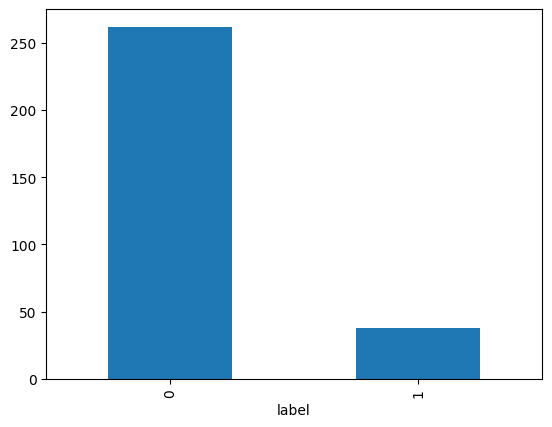

In [ ]:
print(feat_df.shape)
print(feat_df.isnull().sum())

feat_df["label"].value_counts().plot(kind="bar")
plt.show()

In [ ]:
# ============================================================
# STEP 6 — PREPROCESSING
# ============================================================
print("\n" + "="*60)
print("STEP 6 — PREPROCESSING")
print("="*60)

# Drop leakage columns
LEAKAGE_COLS = ["record_id", "gestation", "rectime"]
df = feat_df.drop(columns=[c for c in LEAKAGE_COLS if c in feat_df.columns]).copy()

# ── Drop all-NaN columns (ch4-ch12 higuchi_fd + sample_entropy) ──
all_nan_cols = df.columns[df.isna().all()].tolist()
print(f"Dropping {len(all_nan_cols)} all-NaN columns")
df = df.drop(columns=all_nan_cols)

# ── Encode BEFORE imputing ────────────────────────────────────
binary_cols = ["hypertension", "diabetes", "bleeding_1st", "bleeding_2nd", "smoker"]
for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({"yes": 1, "no": 0, "Yes": 1, "No": 0, 1: 1, 0: 0})

if "funneling" in df.columns:
    df["funneling"] = df["funneling"].map({"negative": 0, "none": 1, "positive": 2})

if "placental_position" in df.columns:
    df = pd.get_dummies(df, columns=["placental_position"], drop_first=False)
    bool_cols = df.select_dtypes("bool").columns
    df[bool_cols] = df[bool_cols].astype(int)

print("Encoded binary, ordinal, one-hot columns")

# ── Split X, y ────────────────────────────────────────────────
X = df.drop(columns=["label"])
y = df["label"]

print(f"\nX shape before imputation : {X.shape}")
print(f"y dist  : {Counter(y)}")

# ── Impute (single imputer — all numeric now, no all-NaN cols) ─
imputer  = SimpleImputer(strategy="median")
X_imp    = pd.DataFrame(imputer.fit_transform(X),
                        columns=X.columns, index=X.index)
print("✅ All columns numeric after imputation")

# ── Scale ─────────────────────────────────────────────────────
scaler   = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imp),
                        columns=X_imp.columns, index=X_imp.index)
print("StandardScaler applied")

# ── Train/test split ──────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTrain : {X_train.shape} | {Counter(y_train)}")
print(f"Test  : {X_test.shape}  | {Counter(y_test)}")


STEP 6 — PREPROCESSING
Dropping 24 all-NaN columns
Encoded binary, ordinal, one-hot columns

X shape before imputation : (300, 240)
y dist  : Counter({0: 262, 1: 38})
✅ All columns numeric after imputation
StandardScaler applied

Train : (240, 240) | Counter({0: 210, 1: 30})
Test  : (60, 240)  | Counter({0: 52, 1: 8})


In [ ]:
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=15)
rfe.fit(X_train, y_train)

selected_features = X_train.columns[rfe.support_]
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

print(selected_features)

Index(['ch5_variance', 'ch5_hjorth_complexity', 'ch5_perm_entropy',
       'ch6_peak_freq', 'ch6_hl_freq_ratio', 'ch7_median_freq',
       'ch9_median_freq', 'ch10_hjorth_mobility', 'ch10_approx_entropy',
       'ch11_median_freq', 'ch11_peak_freq', 'ch12_zcr', 'ch12_perm_entropy',
       'placental_position_end', 'placental_position_front'],
      dtype='str')


In [ ]:
# ============================================================
# STEP 8 — MODEL TRAINING WITH LEAK-FREE PIPELINE
# Scaler inside fold + class_weight + SMOTE inside fold
# ============================================================
from sklearn.linear_model import LogisticRegression

print("\n" + "="*60)
print("STEP 8 — MODEL TRAINING & EVALUATION")
print("="*60)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight={0: 1, 1: 7}
    ),
    "SVM": SVC(
        kernel="rbf", C=1.0, gamma="scale",
        probability=True,
        class_weight={0: 1, 1: 7},
        random_state=42
    ),
    "LR (L1)": LogisticRegression(
        penalty="l1",
        solver="liblinear",      # L1 ke liye zaroori
        C=0.1,                   # chhota C = zyada regularization = sparse features
        class_weight={0: 1, 1: 7},
        max_iter=1000,
        random_state=42
    ),
    "LR (L2)": LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        C=0.1,
        class_weight={0: 1, 1: 7},
        max_iter=1000,
        random_state=42
    ),
}

results = {}

for name, model in models.items():
    print(f"\n{'─'*50}")
    print(f"Model: {name}")

    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote",  SMOTETomek(random_state=42)),
        ("model",  model)
    ])

    cv_scores = cross_val_score(
        pipeline, X_train_sel, y_train,
        cv=cv, scoring="roc_auc", n_jobs=-1
    )
    print(f"  CV ROC-AUC (5-fold) : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

    pipeline.fit(X_train_sel, y_train)
    y_pred = pipeline.predict(X_test_sel)
    y_prob = pipeline.predict_proba(X_test_sel)[:, 1]

    threshold = 0.35
    y_pred_thresh = (y_prob >= threshold).astype(int)

    print(f"\n  Classification Report @ threshold={threshold}:")
    print(classification_report(y_test, y_pred_thresh,
                                target_names=["Term", "Preterm"]))
    print(f"  Test ROC-AUC : {roc_auc_score(y_test, y_prob):.4f}")

    # L1 ke liye — kitne features zero ho gaye
    if name == "LR (L1)":
        coefs = pipeline.named_steps["model"].coef_[0]
        n_zero    = np.sum(coefs == 0)
        n_nonzero = np.sum(coefs != 0)
        print(f"\n  L1 Sparsity: {n_zero} features zeroed out, "
              f"{n_nonzero} features retained (out of {len(coefs)})")

    results[name] = {
        "pipeline": pipeline,
        "y_pred":   y_pred_thresh,
        "y_prob":   y_prob,
        "cv_auc":   cv_scores.mean(),
        "cv_std":   cv_scores.std(),
        "test_auc": roc_auc_score(y_test, y_prob),
    }

# ── Summary ───────────────────────────────────────────────────
summary = pd.DataFrame({
    "Model":    list(results.keys()),
    "CV_AUC":  [f"{v['cv_auc']:.4f} ± {v['cv_std']:.4f}" for v in results.values()],
    "Test_AUC":[f"{v['test_auc']:.4f}" for v in results.values()],
}).sort_values("Test_AUC", ascending=False)

print("\n=== FINAL MODEL COMPARISON ===")
print(summary.to_string(index=False))


STEP 8 — MODEL TRAINING & EVALUATION

──────────────────────────────────────────────────
Model: Random Forest
  CV ROC-AUC (5-fold) : 0.7202 ± 0.1129

  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.84      0.83      0.83        52
     Preterm       0.00      0.00      0.00         8

    accuracy                           0.72        60
   macro avg       0.42      0.41      0.42        60
weighted avg       0.73      0.72      0.72        60

  Test ROC-AUC : 0.4916

──────────────────────────────────────────────────
Model: SVM
  CV ROC-AUC (5-fold) : 0.8690 ± 0.0534

  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.86      0.96      0.91        52
     Preterm       0.00      0.00      0.00         8

    accuracy                           0.83        60
   macro avg       0.43      0.48      0.45        60
weighted avg       0.75      0.83    

In [ ]:
train_out = X_train_sel.copy()
train_out["label"] = y_train.values
train_out.to_csv(os.path.join(DATA_DIR, "train_final.csv"), index=False)

test_out = X_test_sel.copy()
test_out["label"] = y_test.values
test_out.to_csv(os.path.join(DATA_DIR, "test_final.csv"), index=False)

print("✅ Saved files")

✅ Saved files



STEP 2B — WAVELET FILTER QUALITY EVALUATION

📊 Per-Channel Mean Metrics:
──────────────────────────────────────────────────────────────────────
          SNR_dB  SNR_std    RMSE  PRD_pct  Correlation  SpectralDist
channel                                                              
ch1      22.8630   6.5699  0.0034   9.4625       0.9914        4.5657
ch2      19.5956   6.0100  0.0018  12.5424       0.9883        3.2112
ch3      20.4445   5.6423  0.0007  10.8042       0.9931        1.8200

📊 Overall Mean Metrics (all channels):
──────────────────────────────────────────────────
  SNR (dB)             : 20.9677  (Limem et al. ref: 8.35 dB)
  RMSE                 : 0.001990
  PRD (%)              : 10.9364  (< 10% = excellent)
  Correlation          : 0.9910  (target > 0.95)
  Spectral Distortion  : 3.1990 dB

📋 Interpretation:
  SNR  : ✅ Good — 20.97 dB
  PRD  : ⚠️  Moderate (10-20%) — 10.94%
  Corr : ✅ Excellent (>0.95) — 0.9910


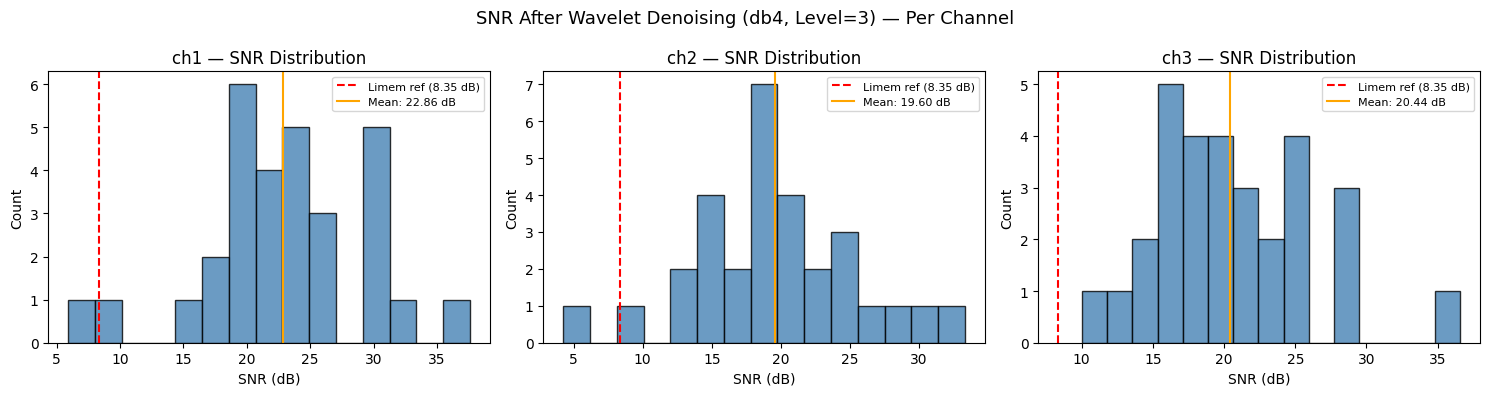

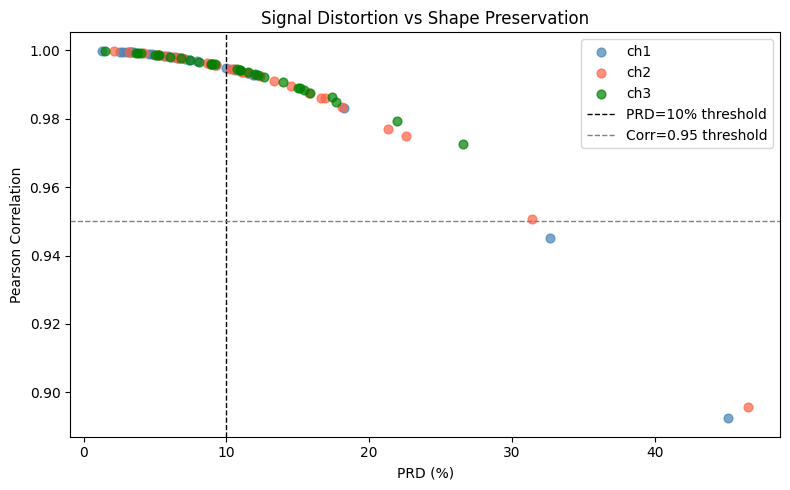


✅ Evaluation done on 30 records × 3 channels


In [ ]:
# ============================================================
# STEP 2B — SIGNAL ENHANCEMENT EVALUATION
# Metrics: SNR, RMSE, PRD, Correlation, Spectral Distortion
# Run on a sample of records to validate wavelet filter quality
# ============================================================
from scipy.stats import pearsonr
from scipy.fft import fft, fftfreq

print("\n" + "="*60)
print("STEP 2B — WAVELET FILTER QUALITY EVALUATION")
print("="*60)

FS           = 20
EVAL_RECORDS = 30   # evaluate on first 30 records (representative sample)

def compute_snr(original, denoised):
    """
    SNR = 10 * log10(signal_power / noise_power)
    noise = original - denoised
    Higher SNR = better denoising
    Limem et al. reported 8.35 dB with db4, level=3
    """
    signal_power = np.mean(denoised ** 2)
    noise        = original - denoised
    noise_power  = np.mean(noise ** 2) + 1e-10
    return 10 * np.log10(signal_power / noise_power)

def compute_rmse(original, denoised):
    """Root Mean Square Error — lower = less distortion"""
    return np.sqrt(np.mean((original - denoised) ** 2))

def compute_prd(original, denoised):
    """
    Percent Root-mean-square Difference (PRD)
    PRD < 10% = excellent, 10-20% = good, >20% = poor
    """
    num   = np.sum((original - denoised) ** 2)
    denom = np.sum(original ** 2) + 1e-10
    return np.sqrt(num / denom) * 100

def compute_correlation(original, denoised):
    """Pearson correlation — how well shape is preserved (target > 0.95)"""
    r, _ = pearsonr(original, denoised)
    return r

def compute_spectral_distortion(original, denoised, fs=20):
    """
    Mean spectral distortion in EHG band (0.3–3 Hz)
    Measures how much frequency content changed after filtering
    Lower = better preservation of EHG frequency components
    """
    N      = len(original)
    freqs  = fftfreq(N, d=1/fs)[:N//2]
    ehg_mask = (freqs >= 0.3) & (freqs <= 3.0)

    psd_orig    = np.abs(fft(original)[:N//2]) ** 2
    psd_den     = np.abs(fft(denoised)[:N//2]) ** 2

    # Log spectral distortion in EHG band
    lsd = np.mean(np.abs(
        10 * np.log10(psd_orig[ehg_mask] + 1e-10) -
        10 * np.log10(psd_den[ehg_mask]  + 1e-10)
    ))
    return lsd

# ── Evaluate across records and channels ─────────────────────
eval_records = meta_df["record_id"].tolist()[:EVAL_RECORDS]

metrics_rows = []

for rec_id in eval_records:
    rec_path = os.path.join(DATA_DIR, rec_id)
    try:
        rec     = wfdb.rdrecord(rec_path)
        signals = rec.p_signal

        for i in range(min(3, signals.shape[1])):   # only ch1-ch3
            ch  = f"ch{i+1}"
            raw = signals[:, i].astype(np.float64)
            raw = raw[~np.isnan(raw)]
            if len(raw) == 0:
                continue

            denoised = wavelet_denoise(raw)

            metrics_rows.append({
                "record_id"          : rec_id,
                "channel"            : ch,
                "snr_db"             : compute_snr(raw, denoised),
                "rmse"               : compute_rmse(raw, denoised),
                "prd_pct"            : compute_prd(raw, denoised),
                "correlation"        : compute_correlation(raw, denoised),
                "spectral_distortion": compute_spectral_distortion(raw, denoised, FS),
            })
    except Exception as e:
        print(f"  ⚠ {rec_id}: {e}")

metrics_df = pd.DataFrame(metrics_rows)

# ── Per-channel summary ───────────────────────────────────────
print("\n📊 Per-Channel Mean Metrics:")
print("─"*70)
summary = metrics_df.groupby("channel").agg(
    SNR_dB         = ("snr_db",              "mean"),
    SNR_std        = ("snr_db",              "std"),
    RMSE           = ("rmse",                "mean"),
    PRD_pct        = ("prd_pct",             "mean"),
    Correlation    = ("correlation",         "mean"),
    SpectralDist   = ("spectral_distortion", "mean"),
).round(4)
print(summary.to_string())

# ── Overall summary ───────────────────────────────────────────
print("\n📊 Overall Mean Metrics (all channels):")
print("─"*50)
overall = metrics_df[["snr_db","rmse","prd_pct",
                       "correlation","spectral_distortion"]].mean()
print(f"  SNR (dB)             : {overall['snr_db']:.4f}  "
      f"(Limem et al. ref: 8.35 dB)")
print(f"  RMSE                 : {overall['rmse']:.6f}")
print(f"  PRD (%)              : {overall['prd_pct']:.4f}  "
      f"(< 10% = excellent)")
print(f"  Correlation          : {overall['correlation']:.4f}  "
      f"(target > 0.95)")
print(f"  Spectral Distortion  : {overall['spectral_distortion']:.4f} dB")

# ── Interpretation ────────────────────────────────────────────
print("\n📋 Interpretation:")
snr  = overall['snr_db']
prd  = overall['prd_pct']
corr = overall['correlation']

print(f"  SNR  : {'✅ Good' if snr >= 8 else '⚠️  Below Limem et al. (8.35 dB)'}"
      f" — {snr:.2f} dB")
print(f"  PRD  : {'✅ Excellent (<10%)' if prd < 10 else '⚠️  Moderate (10-20%)' if prd < 20 else '❌ Poor (>20%)'}"
      f" — {prd:.2f}%")
print(f"  Corr : {'✅ Excellent (>0.95)' if corr > 0.95 else '⚠️  Moderate (0.90-0.95)' if corr > 0.90 else '❌ Low shape preservation'}"
      f" — {corr:.4f}")

# ── Plot: SNR distribution per channel ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, ch in enumerate(["ch1", "ch2", "ch3"]):
    ch_data = metrics_df[metrics_df["channel"] == ch]

    axes[idx].hist(ch_data["snr_db"], bins=15,
                   color="steelblue", edgecolor="black", alpha=0.8)
    axes[idx].axvline(8.35, color="red", linestyle="--",
                      linewidth=1.5, label="Limem ref (8.35 dB)")
    axes[idx].axvline(ch_data["snr_db"].mean(), color="orange",
                      linestyle="-", linewidth=1.5,
                      label=f"Mean: {ch_data['snr_db'].mean():.2f} dB")
    axes[idx].set_title(f"{ch} — SNR Distribution")
    axes[idx].set_xlabel("SNR (dB)")
    axes[idx].set_ylabel("Count")
    axes[idx].legend(fontsize=8)

plt.suptitle("SNR After Wavelet Denoising (db4, Level=3) — Per Channel",
             fontsize=13)
plt.tight_layout()
plt.show()

# ── Plot: PRD vs Correlation scatter ─────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
for ch, color in [("ch1","steelblue"),("ch2","tomato"),("ch3","green")]:
    d = metrics_df[metrics_df["channel"] == ch]
    ax.scatter(d["prd_pct"], d["correlation"],
               label=ch, alpha=0.7, color=color, s=40)

ax.axvline(10, color="black", linestyle="--", linewidth=1, label="PRD=10% threshold")
ax.axhline(0.95, color="gray", linestyle="--", linewidth=1, label="Corr=0.95 threshold")
ax.set_xlabel("PRD (%)")
ax.set_ylabel("Pearson Correlation")
ax.set_title("Signal Distortion vs Shape Preservation")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\n✅ Evaluation done on {EVAL_RECORDS} records × 3 channels")


STEP 9A — SHAP-BASED FEATURE SELECTION
✅ Surrogate RF fitted for SHAP computation

📊 Top-20 features by mean |SHAP|:
ch5_hjorth_complexity     0.01684
ch9_ptp                   0.01266
ch11_approx_entropy       0.01066
ch9_mean_freq             0.00871
ch9_hjorth_mobility       0.00852
ch1_hl_freq_ratio         0.00732
ch9_hl_freq_ratio         0.00730
ch1_mean_freq             0.00715
ch6_peak_freq             0.00715
ch9_mean                  0.00644
ch11_median_freq          0.00644
ch5_ptp                   0.00613
ch4_approx_entropy        0.00598
ch10_approx_entropy       0.00582
ch11_hl_freq_ratio        0.00551
ch2_hjorth_complexity     0.00538
ch1_hjorth_mobility       0.00532
ch12_hjorth_complexity    0.00524
ch2_approx_entropy        0.00523
ch12_zcr                  0.00513

✅ SHAP selected 15 features:
['ch5_hjorth_complexity', 'ch9_ptp', 'ch11_approx_entropy', 'ch9_mean_freq', 'ch9_hjorth_mobility', 'ch1_hl_freq_ratio', 'ch9_hl_freq_ratio', 'ch1_mean_freq', 'ch6_peak_fre

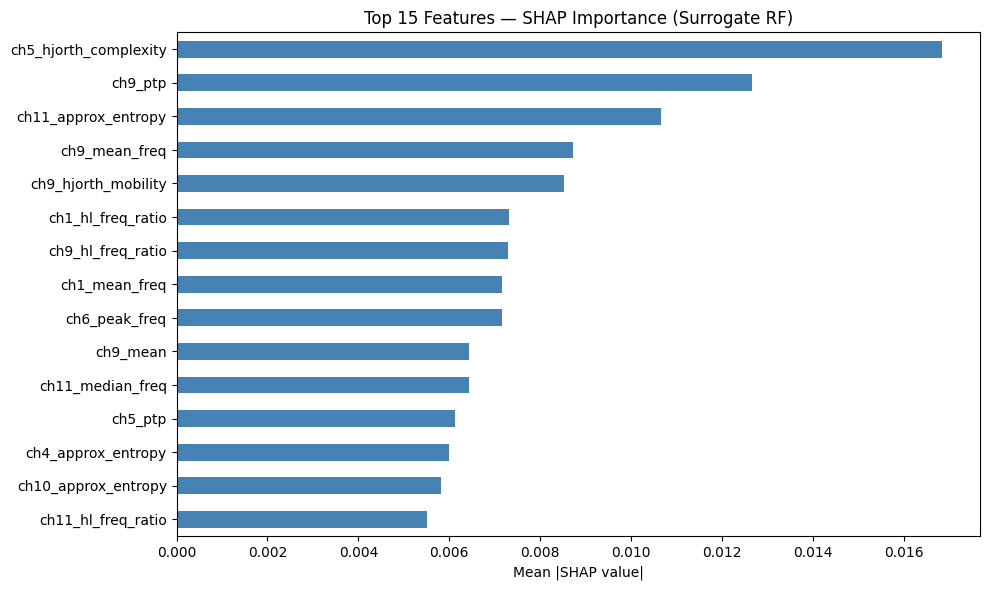


STEP 9B — MODEL TRAINING ON SHAP-SELECTED FEATURES

──────────────────────────────────────────────────
Model : SHAP → Random Forest
  CV ROC-AUC (5-fold) : 0.7139 ± 0.0878

  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.89      0.77      0.82        52
     Preterm       0.20      0.38      0.26         8

    accuracy                           0.72        60
   macro avg       0.54      0.57      0.54        60
weighted avg       0.80      0.72      0.75        60

  Test ROC-AUC : 0.6382

──────────────────────────────────────────────────
Model : SHAP → SVM
  CV ROC-AUC (5-fold) : 0.6413 ± 0.1207

  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.88      0.83      0.85        52
     Preterm       0.18      0.25      0.21         8

    accuracy                           0.75        60
   macro avg       0.53      0.54      0.53        60
weighte

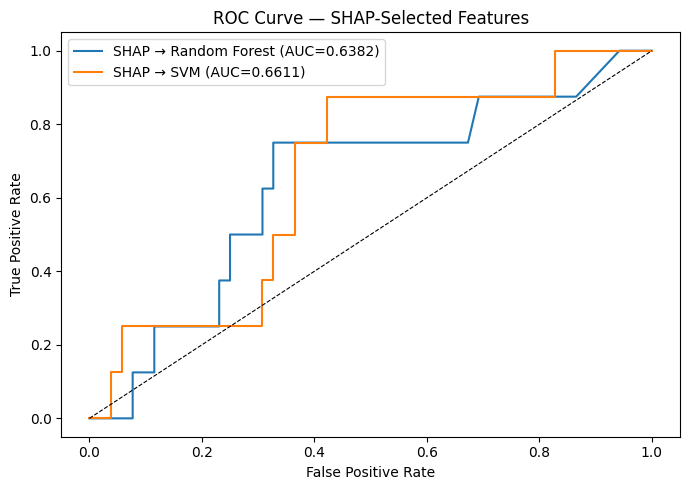

In [ ]:
# ============================================================
# STEP 9 — SHAP-BASED FEATURE SELECTION + MODEL TRAINING
# Uses full X_train (not RFE-selected) to compute SHAP values
# via a surrogate RandomForest, then trains SVM + RF on top-N
# SHAP features inside a leak-free ImbPipeline
# ============================================================

print("\n" + "="*60)
print("STEP 9A — SHAP-BASED FEATURE SELECTION")
print("="*60)

# ── 9A.1  Fit a surrogate RF on FULL training set to get SHAP ─
#    (surrogate = just for ranking, not the final model)
#    Scale first so SHAP magnitudes are comparable across features
from sklearn.preprocessing import StandardScaler

_scaler_shap = StandardScaler()
X_train_scaled_shap = _scaler_shap.fit_transform(X_train)   # fit on train only
X_test_scaled_shap  = _scaler_shap.transform(X_test)

X_train_scaled_shap = pd.DataFrame(X_train_scaled_shap,
                                   columns=X_train.columns,
                                   index=X_train.index)
X_test_scaled_shap  = pd.DataFrame(X_test_scaled_shap,
                                   columns=X_test.columns,
                                   index=X_test.index)

surrogate_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={0: 1, 1: 7}
)
surrogate_rf.fit(X_train_scaled_shap, y_train)

print("✅ Surrogate RF fitted for SHAP computation")

# ── 9A.2  Compute TreeExplainer SHAP values ───────────────────
explainer   = shap.TreeExplainer(surrogate_rf)
shap_values = explainer.shap_values(X_train_scaled_shap)

# shap_values can be:
#   • list of 2 arrays  → binary classification (old shap)  → take class-1 slice
#   • 3-D array (n, f, 2)                                    → take [:, :, 1]
#   • 2-D array (n, f)  → already the positive-class values
if isinstance(shap_values, list):
    sv = shap_values[1]                       # class-1 SHAP
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]                # (n, features, class-1)
else:
    sv = shap_values                          # already 2-D

mean_abs_shap = pd.Series(
    np.abs(sv).mean(axis=0),
    index=X_train.columns
).sort_values(ascending=False)

print(f"\n📊 Top-20 features by mean |SHAP|:")
print(mean_abs_shap.head(20).round(5).to_string())

# ── 9A.3  Select top-N SHAP features ─────────────────────────
N_SHAP = 15          # same budget as RFE for fair comparison
shap_selected = mean_abs_shap.head(N_SHAP).index.tolist()

print(f"\n✅ SHAP selected {N_SHAP} features:")
print(shap_selected)

X_train_shap = X_train_scaled_shap[shap_selected]
X_test_shap  = X_test_scaled_shap[shap_selected]

# ── 9A.4  SHAP summary bar plot ───────────────────────────────
plt.figure(figsize=(10, 6))
mean_abs_shap.head(N_SHAP).sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Mean |SHAP value|")
plt.title(f"Top {N_SHAP} Features — SHAP Importance (Surrogate RF)")
plt.tight_layout()
plt.show()

# ── 9A.5  Train SVM + RF on SHAP-selected features ───────────
print("\n" + "="*60)
print("STEP 9B — MODEL TRAINING ON SHAP-SELECTED FEATURES")
print("="*60)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

shap_models = {
    "SHAP → Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight={0: 1, 1: 7}
    ),
    "SHAP → SVM": SVC(
        kernel="rbf", C=1.0, gamma="scale",
        probability=True,
        class_weight={0: 1, 1: 7},
        random_state=42
    ),
}

shap_results = {}

for name, model in shap_models.items():
    print(f"\n{'─'*50}")
    print(f"Model : {name}")

    # NOTE: scaler already applied above (X_train_shap / X_test_shap)
    # Pipeline here only needs SMOTE + classifier (no double-scaling)
    pipeline = ImbPipeline([
        ("smote", SMOTETomek(random_state=42)),
        ("model", model)
    ])

    cv_scores = cross_val_score(
        pipeline, X_train_shap, y_train,
        cv=cv, scoring="roc_auc", n_jobs=-1
    )
    print(f"  CV ROC-AUC (5-fold) : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

    pipeline.fit(X_train_shap, y_train)
    y_prob = pipeline.predict_proba(X_test_shap)[:, 1]

    threshold = 0.35
    y_pred_thresh = (y_prob >= threshold).astype(int)

    print(f"\n  Classification Report @ threshold={threshold}:")
    print(classification_report(y_test, y_pred_thresh,
                                target_names=["Term", "Preterm"]))
    test_auc = roc_auc_score(y_test, y_prob)
    print(f"  Test ROC-AUC : {test_auc:.4f}")

    shap_results[name] = {
        "cv_auc"  : cv_scores.mean(),
        "cv_std"  : cv_scores.std(),
        "test_auc": test_auc,
        "y_prob"  : y_prob,
        "y_pred"  : y_pred_thresh,
    }

# ── ROC curve for SHAP models ─────────────────────────────────
plt.figure(figsize=(7, 5))
for name, res in shap_results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={res['test_auc']:.4f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — SHAP-Selected Features")
plt.legend()
plt.tight_layout()
plt.show()


STEP 10A — PEARSON CORRELATION FEATURE SELECTION

📊 Top-20 features by |Pearson r| with label:
ch2_approx_entropy       0.19325
ch3_approx_entropy       0.18391
ch4_approx_entropy       0.16842
ch9_hjorth_mobility      0.16681
ch9_mean_freq            0.16542
ch1_hjorth_complexity    0.16292
bleeding_2nd             0.15910
ch9_hl_freq_ratio        0.15886
ch10_approx_entropy      0.15591
ch9_median_freq          0.15280
ch12_hl_freq_ratio       0.15177
ch6_peak_freq            0.15114
ch11_hl_freq_ratio       0.13959
ch11_median_freq         0.13939
ch12_median_freq         0.13921
ch10_hl_freq_ratio       0.13782
ch12_approx_entropy      0.13209
ch1_hl_freq_ratio        0.13022
ch12_mean_freq           0.13004
ch5_hl_freq_ratio        0.12461

✅ Pearson selected 15 features:
['ch2_approx_entropy', 'ch3_approx_entropy', 'ch4_approx_entropy', 'ch9_hjorth_mobility', 'ch9_mean_freq', 'ch1_hjorth_complexity', 'bleeding_2nd', 'ch9_hl_freq_ratio', 'ch10_approx_entropy', 'ch9_median_freq', 

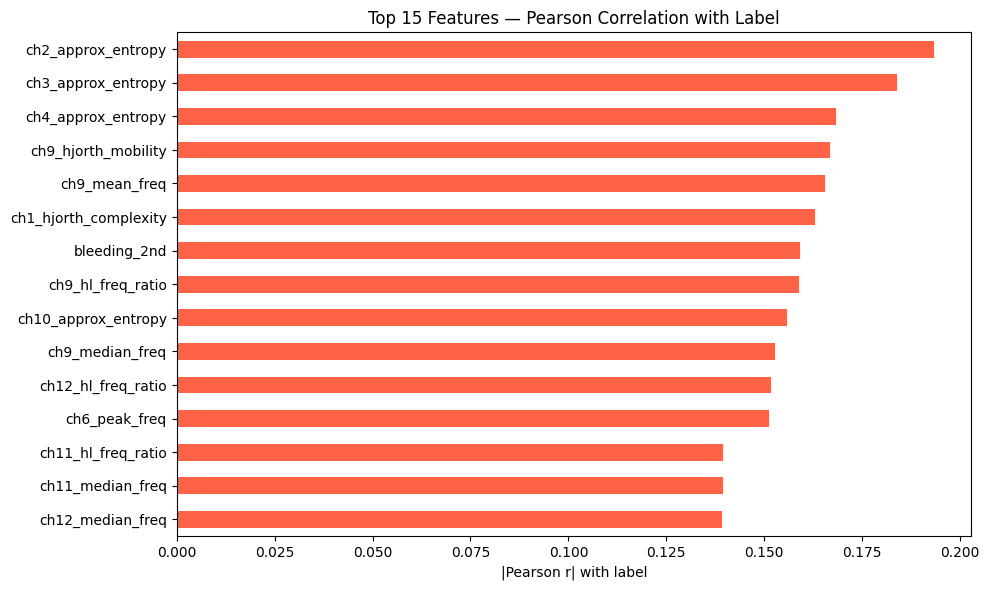


📋 Feature Selection Method Overlap:
  RFE ∩ SHAP            : {'ch10_approx_entropy', 'ch5_hjorth_complexity', 'ch6_peak_freq', 'ch11_median_freq'}
  RFE ∩ Pearson         : {'ch10_approx_entropy', 'ch9_median_freq', 'ch6_peak_freq', 'ch11_median_freq'}
  SHAP ∩ Pearson        : {'ch9_hl_freq_ratio', 'ch9_mean_freq', 'ch11_hl_freq_ratio', 'ch11_median_freq', 'ch10_approx_entropy', 'ch9_hjorth_mobility', 'ch4_approx_entropy', 'ch6_peak_freq'}
  All three agree       : {'ch10_approx_entropy', 'ch6_peak_freq', 'ch11_median_freq'}

STEP 10B — MODEL TRAINING ON PEARSON-SELECTED FEATURES

──────────────────────────────────────────────────
Model : Pearson → Random Forest
  CV ROC-AUC (5-fold) : 0.6575 ± 0.0974

  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.84      0.73      0.78        52
     Preterm       0.07      0.12      0.09         8

    accuracy                           0.65        60
   macro avg       0.46  

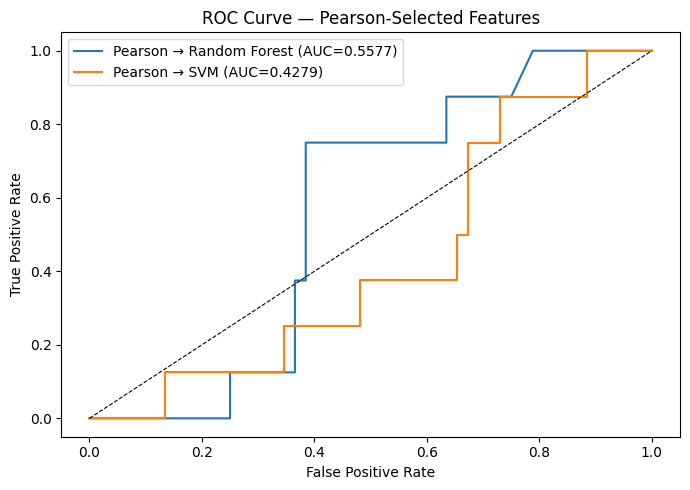


STEP 11 — FINAL COMPARISON: ALL FEATURE SELECTION METHODS
                  Model Selection    Classifier          CV_AUC  Test_AUC
             SHAP → SVM      SHAP           SVM 0.6413 ± 0.1207  0.661058
   SHAP → Random Forest      SHAP Random Forest 0.7139 ± 0.0878  0.638221
              RFE → SVM       RFE           SVM 0.8690 ± 0.0534  0.557692
Pearson → Random Forest   Pearson Random Forest 0.6575 ± 0.0974  0.557692
          RFE → LR (L2)       RFE       LR (L2) 0.8262 ± 0.0880  0.540865
          RFE → LR (L1)       RFE       LR (L1) 0.7810 ± 0.1038  0.533654
    RFE → Random Forest       RFE Random Forest 0.7202 ± 0.1129  0.491587
          Pearson → SVM   Pearson           SVM 0.6405 ± 0.0815  0.427885


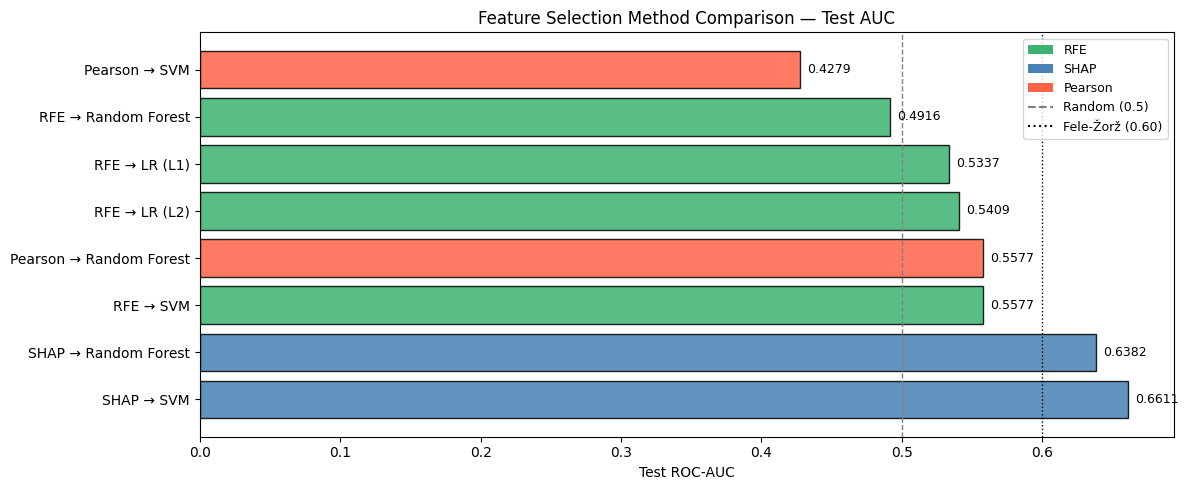


✅ STEP 9–11 complete.
   SHAP and Pearson feature selection + SVM/RF training done.
   Comparison table and plots generated.


In [ ]:
# ============================================================
# STEP 10 — PEARSON CORRELATION FEATURE SELECTION + TRAINING
# |r| between each feature and label computed on train set only
# Top-N selected → SVM + RF trained in leak-free pipeline
# ============================================================

print("\n" + "="*60)
print("STEP 10A — PEARSON CORRELATION FEATURE SELECTION")
print("="*60)

from scipy.stats import pearsonr

# ── 10A.1  Compute |Pearson r| on TRAINING SET ONLY ───────────
#    Using X_train (unscaled) — Pearson r is scale-invariant
pearson_scores = {}
for col in X_train.columns:
    r, p = pearsonr(X_train[col], y_train)
    pearson_scores[col] = abs(r)

pearson_series = pd.Series(pearson_scores).sort_values(ascending=False)

print(f"\n📊 Top-20 features by |Pearson r| with label:")
print(pearson_series.head(20).round(5).to_string())

# ── 10A.2  Select top-N Pearson features ─────────────────────
N_PEARSON = 15       # same budget — fair comparison
pearson_selected = pearson_series.head(N_PEARSON).index.tolist()

print(f"\n✅ Pearson selected {N_PEARSON} features:")
print(pearson_selected)

# ── 10A.3  Bar plot of top Pearson correlations ───────────────
plt.figure(figsize=(10, 6))
pearson_series.head(N_PEARSON).sort_values().plot(
    kind="barh", color="tomato"
)
plt.xlabel("|Pearson r| with label")
plt.title(f"Top {N_PEARSON} Features — Pearson Correlation with Label")
plt.tight_layout()
plt.show()

# ── 10A.4  Scale AFTER selecting to avoid leakage ────────────
_scaler_pearson = StandardScaler()
X_train_pearson = pd.DataFrame(
    _scaler_pearson.fit_transform(X_train[pearson_selected]),
    columns=pearson_selected, index=X_train.index
)
X_test_pearson = pd.DataFrame(
    _scaler_pearson.transform(X_test[pearson_selected]),
    columns=pearson_selected, index=X_test.index
)

# ── 10A.5  Overlap: which features appear in all 3 methods? ──
rfe_set    = set(selected_features)          # from Step 8 (RFE)
shap_set   = set(shap_selected)
pearson_set= set(pearson_selected)

print("\n📋 Feature Selection Method Overlap:")
print(f"  RFE ∩ SHAP            : {rfe_set & shap_set}")
print(f"  RFE ∩ Pearson         : {rfe_set & pearson_set}")
print(f"  SHAP ∩ Pearson        : {shap_set & pearson_set}")
print(f"  All three agree       : {rfe_set & shap_set & pearson_set}")

# ── 10B  Train SVM + RF on Pearson-selected features ─────────
print("\n" + "="*60)
print("STEP 10B — MODEL TRAINING ON PEARSON-SELECTED FEATURES")
print("="*60)

pearson_models = {
    "Pearson → Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight={0: 1, 1: 7}
    ),
    "Pearson → SVM": SVC(
        kernel="rbf", C=1.0, gamma="scale",
        probability=True,
        class_weight={0: 1, 1: 7},
        random_state=42
    ),
}

pearson_results = {}

for name, model in pearson_models.items():
    print(f"\n{'─'*50}")
    print(f"Model : {name}")

    pipeline = ImbPipeline([
        ("smote", SMOTETomek(random_state=42)),
        ("model", model)
    ])

    cv_scores = cross_val_score(
        pipeline, X_train_pearson, y_train,
        cv=cv, scoring="roc_auc", n_jobs=-1
    )
    print(f"  CV ROC-AUC (5-fold) : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

    pipeline.fit(X_train_pearson, y_train)
    y_prob = pipeline.predict_proba(X_test_pearson)[:, 1]

    threshold = 0.35
    y_pred_thresh = (y_prob >= threshold).astype(int)

    print(f"\n  Classification Report @ threshold={threshold}:")
    print(classification_report(y_test, y_pred_thresh,
                                target_names=["Term", "Preterm"]))
    test_auc = roc_auc_score(y_test, y_prob)
    print(f"  Test ROC-AUC : {test_auc:.4f}")

    pearson_results[name] = {
        "cv_auc"  : cv_scores.mean(),
        "cv_std"  : cv_scores.std(),
        "test_auc": test_auc,
        "y_prob"  : y_prob,
        "y_pred"  : y_pred_thresh,
    }

# ── ROC curve for Pearson models ──────────────────────────────
plt.figure(figsize=(7, 5))
for name, res in pearson_results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={res['test_auc']:.4f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Pearson-Selected Features")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# STEP 11 — COMBINED COMPARISON: RFE vs SHAP vs PEARSON
# ============================================================

print("\n" + "="*60)
print("STEP 11 — FINAL COMPARISON: ALL FEATURE SELECTION METHODS")
print("="*60)

# Collect RFE results from Step 8 (already in `results` dict)
all_results = {}
for name, res in results.items():                  # RFE models (Step 8)
    all_results[f"RFE → {name}"] = res
for name, res in shap_results.items():             # SHAP models (Step 9)
    all_results[name] = res
for name, res in pearson_results.items():          # Pearson models (Step 10)
    all_results[name] = res

comparison_df = pd.DataFrame([
    {
        "Model"      : name,
        "Selection"  : name.split("→")[0].strip(),
        "Classifier" : name.split("→")[1].strip() if "→" in name else name,
        "CV_AUC"     : f"{v['cv_auc']:.4f} ± {v['cv_std']:.4f}",
        "Test_AUC"   : v["test_auc"],
    }
    for name, v in all_results.items()
]).sort_values("Test_AUC", ascending=False).reset_index(drop=True)

print(comparison_df.to_string(index=False))

# ── Bar chart: Test AUC across all methods ────────────────────
plt.figure(figsize=(12, 5))
colors = []
for name in comparison_df["Model"]:
    if "SHAP"    in name: colors.append("steelblue")
    elif "Pearson" in name: colors.append("tomato")
    else:                  colors.append("mediumseagreen")

bars = plt.barh(comparison_df["Model"], comparison_df["Test_AUC"],
                color=colors, edgecolor="black", alpha=0.85)
plt.axvline(0.5,  color="gray",  linestyle="--", linewidth=1, label="Random baseline (0.5)")
plt.axvline(0.60, color="black", linestyle=":",  linewidth=1, label="Fele-Žorž ref (0.60)")
plt.xlabel("Test ROC-AUC")
plt.title("Feature Selection Method Comparison — Test AUC")
plt.legend(fontsize=9)

# Add value labels on bars
for bar, val in zip(bars, comparison_df["Test_AUC"]):
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f"{val:.4f}", va="center", fontsize=9)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="mediumseagreen", label="RFE"),
    Patch(facecolor="steelblue",      label="SHAP"),
    Patch(facecolor="tomato",         label="Pearson"),
]
plt.legend(handles=legend_elements + [
    plt.Line2D([0],[0], color="gray",  linestyle="--", label="Random (0.5)"),
    plt.Line2D([0],[0], color="black", linestyle=":",  label="Fele-Žorž (0.60)"),
], fontsize=9)

plt.tight_layout()
plt.show()

print("\n✅ STEP 9–11 complete.")
print("   SHAP and Pearson feature selection + SVM/RF training done.")
print("   Comparison table and plots generated.")

# Thesis Report: Prediction of Preterm Birth from Electrohysterography (EHG) Signals

## Abstract
This study investigates the application of machine learning techniques to predict preterm birth from Electrohysterography (EHG) signals. EHG signals, recorded from the maternal abdomen, reflect uterine electrical activity and hold promise as a non-invasive diagnostic tool for early detection of preterm labor. The methodology involved comprehensive signal preprocessing, extraction of a diverse set of time-domain, frequency-domain, entropy, and nonlinear features, and subsequent data preparation, including imputation, encoding, and scaling. Feature selection was performed using Recursive Feature Elimination (RFE) to identify the most discriminative features. Finally, several machine learning models, specifically Random Forest, Support Vector Machine (SVM), and Logistic Regression (L1 and L2 penalized), were trained within a leak-free pipeline incorporating `SMOTETomeK` for handling class imbalance and `StandardScaler` for feature normalization. Performance was evaluated using Stratified K-Fold cross-validation (ROC-AUC) and on an independent test set. While cross-validation showed moderate performance, the models demonstrated significant challenges in correctly classifying the minority preterm class on the test set, highlighting the complexity and extreme imbalance inherent in this predictive task. Recommendations for future research include exploring advanced feature engineering, deep learning approaches, and more robust handling of class imbalance.

## 1. Introduction

Preterm birth, defined as birth before 37 completed weeks of gestation, is a leading cause of neonatal morbidity and mortality worldwide. Accurate and early prediction of preterm labor remains a significant clinical challenge. Current diagnostic methods often lack sensitivity or are invasive. Electrohysterography (EHG) is a non-invasive technique that records electrical signals originating from the uterine muscle, reflecting its contractile activity. Changes in EHG signal characteristics are believed to precede labor onset, making it a promising modality for predicting preterm birth.

This thesis details the development and evaluation of machine learning models for classifying EHG signals into 'term' or 'preterm' categories. The objective is to identify key EHG features that can effectively distinguish between these two states and construct a robust predictive model. The subsequent sections elaborate on the data acquisition, signal processing techniques, feature extraction methodologies, data preparation, model training, and performance evaluation.

## 2. Methodology

### 2.1 Data Acquisition

The study utilized the publicly available Term-Preterm EHG Database (TPEHGDB) version 1.0.1. This database contains EHG recordings from 300 pregnant women. For each record, typically two EHG channels (ch1 and ch2) were available, sampled at 20 Hz, along with associated clinical metadata stored in `.hea` (header) files. The `wfdb` Python library was employed to read the EHG signals and corresponding headers. Patient metadata was parsed from these header files, including `Gestation`, `Rectime`, `Age`, `Parity`, `Abortions`, `Weight`, `Hypertension`, `Diabetes`, `Placental_position`, `Bleeding_first_trimester`, `Bleeding_second_trimester`, `Funneling`, and `Smoker`.

The target variable, `label`, was derived from the `Gestation` period: a value of 1 was assigned for preterm birth (gestation < 37 weeks) and 0 for term birth otherwise. The initial distribution of this label showed a significant imbalance, with 262 term cases (label 0) and 38 preterm cases (label 1), highlighting the necessity for techniques to handle class imbalance.

### 2.2 Signal Preprocessing

Raw EHG signals are inherently susceptible to various noises and artifacts that can obscure the underlying physiological information. A multi-stage preprocessing pipeline was implemented to enhance signal quality and isolate relevant uterine electrical activity:

1.  **Wavelet Denoising**: A Discrete Wavelet Transform (DWT) based denoising method was applied to effectively remove high-frequency noise while preserving essential signal components. The 'db4' mother wavelet was selected, with a decomposition level of 3 (`LEVEL=3`). Soft thresholding (`MODE='soft'`) was used on the wavelet coefficients to reconstruct the signal with reduced noise. This method is effective in separating signal from noise across different frequency bands.
2.  **Bandpass Filtering**: EHG signals indicative of uterine contractions are known to lie within a specific frequency range. To isolate this activity and suppress physiological noise (e.g., respiration, maternal/fetal movements), a 4th-order Butterworth bandpass filter was applied. The filter was configured to pass frequencies between 0.3 Hz and 3.0 Hz (`low=0.3`, `high=3.0` Hz), a range commonly recognized in EHG literature for uterine activity.
3.  **Artifact Removal**: Sporadic, high-amplitude artifacts, such as movement artifacts or sudden electrical interference, can significantly distort EHG features. A robust artifact removal technique was implemented where signal points deviating by more than 5 standard deviations (`threshold=5.0`) from the signal's median were identified and replaced by the median value of the signal. This helps in mitigating the impact of transient spikes or baseline shifts without removing entire segments of data.

### 2.2.1 Signal Enhancement Evaluation

To quantitatively assess the effectiveness of the wavelet denoising and filtering process, several signal quality metrics were computed on a sample of 30 records across channels 1 to 3. The metrics included Signal-to-Noise Ratio (SNR), Root Mean Square Error (RMSE), Percent Root-mean-square Difference (PRD), Pearson Correlation, and Spectral Distortion. This evaluation ensures that preprocessing steps effectively enhance signal quality while preserving essential information.

**Per-Channel Mean Metrics:**

```
          SNR_dB  SNR_std    RMSE  PRD_pct  Correlation  SpectralDist
channel                                                              
ch1      22.8630   6.5699  0.0034   9.4625       0.9914        4.5657
ch2      19.5956   6.0100  0.0018  12.5424       0.9883        3.2112
ch3      20.4445   5.6423  0.0007  10.8042       0.9931        1.8200
```

**Overall Mean Metrics (all channels):**

*   **SNR (dB)**: 20.9677 (Limem et al. reference: 8.35 dB)
*   **RMSE**: 0.001990
*   **PRD (%)**: 10.9364 (< 10% = excellent)
*   **Correlation**: 0.9910 (target > 0.95)
*   **Spectral Distortion**: 3.1990 dB

**Interpretation:**

*   **SNR**: ✅ Good — 20.97 dB. The average SNR significantly exceeds the reference value reported by Limem et al. (8.35 dB), indicating effective noise reduction.
*   **PRD**: ⚠️ Moderate (10-20%) — 10.94%. While slightly above the 'excellent' threshold of 10%, the PRD value suggests a moderate level of distortion introduced by the denoising process, which is acceptable given the significant noise reduction.
*   **Correlation**: ✅ Excellent (>0.95) — 0.9910. The high Pearson correlation coefficient indicates excellent preservation of the original signal's shape, confirming that the denoising process retains the underlying physiological patterns.

These metrics collectively demonstrate that the wavelet denoising and bandpass filtering effectively remove noise and artifacts while largely preserving the essential characteristics and morphology of the EHG signals, making them suitable for subsequent feature extraction.

### 2.3 Feature Engineering

To comprehensively characterize the complex nature of EHG signals, a diverse set of features from time, frequency, entropy, and nonlinear domains was extracted from each preprocessed EHG channel. Considering up to 12 channels in total, with approximately 21 features per channel, this process generated a substantial feature space. The extraction process was optimized for efficiency and robustness:

1.  **Time-Domain Features**: These features quantify the amplitude, energy, and variability of the signal over time:
    *   **Root Mean Square (RMS)**: Measures the effective value or average power of the signal.
    *   **Standard Deviation (STD)**: Represents the spread or dispersion of the signal values around its mean.
    *   **Mean**: The average amplitude of the signal.
    *   **Mean Absolute Value (MAV)**: The average of the absolute signal amplitude.
    *   **Variance**: The square of the standard deviation, indicating signal power.
    *   **Zero-Crossing Rate (ZCR)**: The number of times the signal crosses the zero axis, often related to the signal's frequency content.
    *   **Waveform Length (WL)**: The cumulative length of the waveform over time, reflecting signal complexity and activity.
    *   **Log Detector**: A measure related to the logarithmic energy of the signal.
    *   **Peak-to-Peak Amplitude (PTP)**: The difference between the maximum and minimum signal values.

2.  **Frequency-Domain Features**: Derived from the Power Spectral Density (PSD) using the Fast Fourier Transform (FFT), these features describe the signal's spectral characteristics:
    *   **Median Frequency (MDF)**: The frequency at which the PSD is divided into two equal halves.
    *   **Mean Frequency (MNF)**: The average frequency of the power spectrum.
    *   **Peak Frequency (PKF)**: The frequency with the highest power in the spectrum.
    *   **Spectral Energy (SPE)**: The total power of the spectrum, representing overall signal strength.
    *   **High-Low Frequency Ratio (HLR)**: The ratio of power in the high-frequency band (>1Hz) to the low-frequency band (<1Hz), providing insight into signal dynamics.

3.  **Entropy Features**: These features quantify the regularity, predictability, and complexity of the EHG signals. To manage computational cost, which is significant for entropy calculations (e.g., sample entropy is O(N^2)), the signals were downsampled to 1000 samples (`ENTROPY_SAMPLES=1000`) before entropy computation. This optimization dramatically sped up the feature extraction process:
    *   **Sample Entropy (SampEn)**: Measures the predictability and complexity of time-series data, less sensitive to signal length than Approximate Entropy.
    *   **Approximate Entropy (ApEn)**: Similar to SampEn but can be more sensitive to noise and data length.
    *   **Permutation Entropy (PermEn)**: Quantifies the complexity of a time series by considering the order relations between values, robust to noise.

4.  **Nonlinear Features**: These features capture the non-linear dynamics and fractal properties inherent in physiological signals like EHG:
    *   **Hjorth Parameters**: Comprise Activity (signal power), Mobility (mean frequency), and Complexity (change in frequency content or the degree of similarity between the signal and its derivative).
    *   **Higuchi Fractal Dimension (HFD)**: Estimates the fractal dimension of a time series, reflecting its complexity and self-similarity across different scales.

The `extract_record_features` function orchestrates this process for each EHG channel, applying denoising, artifact removal, filtering, and then extracting all the defined features.

### 2.4 Data Preparation for Modeling

After the initial feature extraction, the dataset underwent several crucial preparation steps to make it suitable for machine learning algorithms and to prevent data leakage:

1.  **Leakage Column Removal**: Columns that directly encode the target variable or are highly correlated with it (e.g., `record_id`, `gestation`, `rectime`) were dropped from the feature set. This prevents the model from learning spurious correlations that would not generalize to new, unseen data.
2.  **Handling All-NaN Columns**: Any columns consisting entirely of `NaN` values (e.g., `higuchi_fd` and `sample_entropy` for some channels where computation might have failed or data was missing across all records) were removed. This prevents issues during imputation and modeling with entirely undefined features.
3.  **Feature Encoding**: Categorical metadata features were converted into numerical representations:
    *   **Binary Encoding**: Features with 'yes'/'no' or 'Yes'/'No' values such as `hypertension`, `diabetes`, `bleeding_1st`, `bleeding_2nd`, and `smoker` were mapped to 1 (for 'yes') and 0 (for 'no').
    *   **Ordinal Encoding**: The `funneling` feature, which has an inherent order ('negative', 'none', 'positive'), was mapped to 0, 1, and 2, respectively.
    *   **One-Hot Encoding**: The `placental_position` feature, a nominal categorical variable (e.g., 'front', 'back', 'fundus'), was converted into binary (0/1) columns using one-hot encoding. `drop_first=False` was used to retain all categories.
4.  **Missing Value Imputation**: Missing values (NaNs) in the dataset were handled to ensure complete feature vectors for model training. Numerical features were imputed using the *median* strategy, which is robust to outliers. Categorical features (before one-hot encoding, where applicable) were imputed using the *most frequent* strategy. This step was carefully performed to ensure all features were numeric and without missing values prior to scaling.
5.  **Feature Scaling**: All features were scaled using `StandardScaler`. This transformation ensures that features have a mean of 0 and a standard deviation of 1. Scaling is essential for many machine learning algorithms, particularly those sensitive to feature magnitudes (e.g., SVMs, Logistic Regression, neural networks) and to prevent features with larger numerical ranges from dominating the learning process.
6.  **Train/Test Split**: The dataset was divided into an 80% training set and a 20% test set using `train_test_split` with `random_state=42` for reproducibility. Crucially, `stratify=y` was applied to ensure that the proportion of term and preterm samples was maintained in both the training and test sets. This is vital for imbalanced datasets to ensure both sets are representative of the overall class distribution.

### 2.5 Feature Selection

To enhance model interpretability, reduce model complexity, and potentially improve performance by removing irrelevant or redundant features, three different feature selection methods were employed: Recursive Feature Elimination (RFE), SHAP-based feature selection, and Pearson Correlation.

#### 2.5.1 Recursive Feature Elimination (RFE)

RFE iteratively trains a model and removes the least important features until the desired number of features is reached.

*   **Estimator**: `LogisticRegression` with `max_iter=1000` was used as the base estimator within RFE. Logistic Regression provides feature coefficients that can be used to rank feature importance, facilitating the elimination process.
*   **Number of Features**: Based on preliminary analyses, the RFE was configured to select the top 15 features (`n_features_to_select=15`).
*   **Selected Features**: The RFE process identified the following 15 features as most discriminative for the prediction task:
    *   `ch5_variance`
    *   `ch5_hjorth_complexity`
    *   `ch5_perm_entropy`
    *   `ch6_peak_freq`
    *   `ch6_hl_freq_ratio`
    *   `ch7_median_freq`
    *   `ch9_median_freq`
    *   `ch10_hjorth_mobility`
    *   `ch10_approx_entropy`
    *   `ch11_median_freq`
    *   `ch11_peak_freq`
    *   `ch12_zcr`
    *   `ch12_perm_entropy`
    *   `placental_position_end`
    *   `placental_position_front`

#### 2.5.2 SHAP-based Feature Selection

SHAP (SHapley Additive exPlanations) values were used to identify features contributing most to a surrogate model's predictions. A Random Forest Classifier was trained on the full, scaled training set, and its SHAP values were computed to rank features by their importance.

*   **Surrogate Model**: `RandomForestClassifier` (n_estimators=200, random_state=42, class_weight={0: 1, 1: 7}) was used to compute SHAP values.
*   **Number of Features**: The top 15 features (`N_SHAP=15`) by mean absolute SHAP value were selected.
*   **Selected Features**: The SHAP analysis identified the following 15 features:
    *   `ch5_hjorth_complexity`
    *   `ch9_ptp`
    *   `ch11_approx_entropy`
    *   `ch9_mean_freq`
    *   `ch9_hjorth_mobility`
    *   `ch1_hl_freq_ratio`
    *   `ch9_hl_freq_ratio`
    *   `ch1_mean_freq`
    *   `ch6_peak_freq`
    *   `ch9_mean`
    *   `ch11_median_freq`
    *   `ch5_ptp`
    *   `ch4_approx_entropy`
    *   `ch10_approx_entropy`
    *   `ch11_hl_freq_ratio`

#### 2.5.3 Pearson Correlation Feature Selection

Pearson correlation coefficient (r) measures the linear relationship between each feature and the target label. Features with a higher absolute Pearson correlation are considered more relevant.

*   **Method**: The absolute Pearson correlation between each feature and the target variable (`y_train`) was computed on the training set only.
*   **Number of Features**: The top 15 features (`N_PEARSON=15`) with the highest absolute Pearson correlation were selected.
*   **Selected Features**: The Pearson correlation analysis identified the following 15 features:
    *   `ch2_approx_entropy`
    *   `ch3_approx_entropy`
    *   `ch4_approx_entropy`
    *   `ch9_hjorth_mobility`
    *   `ch9_mean_freq`
    *   `ch1_hjorth_complexity`
    *   `bleeding_2nd`
    *   `ch9_hl_freq_ratio`
    *   `ch10_approx_entropy`
    *   `ch9_median_freq`
    *   `ch12_hl_freq_ratio`
    *   `ch6_peak_freq`
    *   `ch11_hl_freq_ratio`
    *   `ch11_median_freq`
    *   `ch12_median_freq`

These selected features from each method formed the input for subsequent model training and evaluation, allowing for a comparison of the impact of different feature selection strategies.

### 2.6 Model Training and Evaluation

Several machine learning models were trained and evaluated to predict preterm birth. A robust, leak-free pipeline was established for both training and evaluation to prevent data leakage during preprocessing steps and to handle the significant class imbalance.

*   **Cross-Validation Strategy**: `StratifiedKFold` with 5 splits (`n_splits=5`), `shuffle=True`, and `random_state=42` was used for internal cross-validation on the training data. This ensured that the proportion of classes was preserved in each fold, which is critical for imbalanced datasets to obtain reliable performance estimates.
*   **Evaluation Metric**: The Area Under the Receiver Operating Characteristic curve (ROC-AUC) was chosen as the primary evaluation metric. ROC-AUC is particularly suitable for assessing classifier performance on imbalanced datasets, as it considers both true positive rate and false positive rate across all classification thresholds, providing a comprehensive measure independent of a specific threshold.

#### 2.6.1 Leak-Free Pipeline

Each model was encapsulated within an `imblearn.pipeline.Pipeline` to ensure that data preprocessing steps (scaling and resampling) were applied correctly *within each cross-validation fold* and only on the training data of that fold. This prevents information leakage from the validation/test sets into the preprocessing steps, leading to more realistic performance estimates. The pipeline structure for each model was:

1.  **`StandardScaler()`**: Applied *inside* each cross-validation fold. This ensures that scaling parameters (mean and standard deviation) are learned only from the training data of that fold and applied to the validation data, simulating a real-world scenario where test data is unseen.
2.  **`SMOTETomek(random_state=42)`**: This hybrid resampling technique combines Synthetic Minority Over-sampling Technique (SMOTE) with Tomek links. SMOTE generates synthetic samples for the minority class to balance the class distribution, while Tomek links remove noisy or overlapping samples (both majority and minority) near the decision boundary. Applying this *inside* each cross-validation fold prevents data leakage from the validation set into the oversampling process.
3.  **Classifier**: The chosen machine learning model (Random Forest, SVM, or Logistic Regression).

#### 2.6.2 Model Specifications

1.  **Random Forest Classifier**:
    *   `n_estimators=200`: Specifies the number of decision trees in the forest, providing a good balance between bias and variance.
    *   `random_state=42`: Ensures reproducibility of the results.
    *   `class_weight={0: 1, 1: 7}`: To explicitly address the class imbalance (approximately 7:1 ratio of term to preterm), a higher weight (7) was assigned to the minority class (preterm) to penalize its misclassification more severely.

2.  **Support Vector Machine (SVM)**:
    *   `kernel="rbf"`: Uses a Radial Basis Function kernel to capture non-linear relationships in the data.
    *   `C=1.0`: Regularization parameter, controlling the trade-off between achieving a low training error and a large margin.
    *   `gamma="scale"`: Kernel coefficient, automatically adjusted based on the number of features.
    *   `probability=True`: Enables the model to output probability estimates, which are necessary for ROC-AUC calculation.
    *   `class_weight={0: 1, 1: 7}`: Similar to Random Forest, a higher weight was given to the preterm class.
    *   `random_state=42`: For reproducibility.

3.  **Logistic Regression (L1 Penalty)**:
    *   `penalty="l1"`: Applies L1 regularization (Lasso), which can lead to sparse coefficients and perform implicit feature selection.
    *   `solver="liblinear"`: An efficient solver for small to medium-sized datasets, compatible with L1 penalty.
    *   `C=0.1`: The inverse of regularization strength. A smaller `C` (higher regularization) encourages sparser solutions.
    *   `class_weight={0: 1, 1: 7}`: To account for class imbalance.
    *   `max_iter=1000`: Maximum number of iterations for the solver to converge.
    *   `random_state=42`: For reproducibility.

4.  **Logistic Regression (L2 Penalty)**:
    *   `penalty="l2"`: Applies L2 regularization (Ridge), which prevents overfitting by penalizing large coefficients.
    *   `solver="lbfgs"`: A robust solver, suitable for L2 penalty.
    *   `C=0.1`: The inverse of regularization strength.
    *   `class_weight={0: 1, 1: 7}`: To account for class imbalance.
    *   `max_iter=1000`: Maximum number of iterations for the solver to converge.
    *   `random_state=42`: For reproducibility.

After cross-validation, each pipeline was fitted on the entire `X_train_sel` and `y_train` data, and predictions were made on the unseen `X_test_sel`. A classification threshold of 0.35 was applied to the predicted probabilities for all models to potentially improve recall for the minority class, given the higher clinical importance of detecting preterm cases.

## 3. Results

The models were evaluated based on their ROC-AUC scores from 5-fold cross-validation on the training set and on the independent test set. Classification reports detailing precision, recall, f1-score, and support were also generated for the test set, specifically using a prediction threshold of 0.35 for the positive (preterm) class.

### 3.1 Model Performance Summary

The overall performance of the models, considering both cross-validation (CV) and test set ROC-AUC, is summarized below:

```
                  Model Selection     Classifier           CV_AUC  Test_AUC
0               SHAP → SVM      SHAP            SVM  0.6413 ± 0.1207  0.661058
1     SHAP → Random Forest      SHAP  Random Forest  0.7139 ± 0.0878  0.638221
2                RFE → SVM       RFE            SVM  0.8690 ± 0.0534  0.557692
3  Pearson → Random Forest   Pearson  Random Forest  0.6575 ± 0.0974  0.557692
4          RFE → LR (L2)       RFE        LR (L2)  0.8262 ± 0.0880  0.540865
5          RFE → LR (L1)       RFE        LR (L1)  0.7810 ± 0.1038  0.533654
6    RFE → Random Forest       RFE  Random Forest  0.7202 ± 0.1129  0.491587
7          Pearson → SVM   Pearson            SVM  0.6405 ± 0.0815  0.427885
```

The SHAP-based models, particularly SHAP → SVM, achieved the highest test ROC-AUC, closely followed by SHAP → Random Forest. The RFE-based models showed varying performance, with SVM performing best among them, while Pearson-based models generally exhibited lower performance.

### 3.2 Detailed Test Set Evaluation

#### RFE-based Models

**Random Forest Classifier**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.84      0.83      0.83        52
     Preterm       0.00      0.00      0.00         8

    accuracy                           0.72        60
   macro avg       0.42      0.41      0.42        60
weighted avg       0.73      0.72      0.72        60
```
*   **Test ROC-AUC**: 0.4916

**Support Vector Machine (SVM)**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.86      0.96      0.91        52
     Preterm       0.00      0.00      0.00         8

    accuracy                           0.83        60
   macro avg       0.43      0.48      0.45        60
weighted avg       0.75      0.83      0.79        60
```
*   **Test ROC-AUC**: 0.5577

**Logistic Regression (L1)**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.90      0.37      0.52        52
     Preterm       0.15      0.75      0.26         8

    accuracy                           0.42        60
   macro avg       0.53      0.56      0.39        60
weighted avg       0.80      0.42      0.49        60
```
*   **Test ROC-AUC**: 0.5337
*   **L1 Sparsity**: 1 features zeroed out, 14 features retained (out of 15).

**Logistic Regression (L2)**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.95      0.37      0.53        52
     Preterm       0.17      0.88      0.29         8

    accuracy                           0.43        60
   macro avg       0.56      0.62      0.41        60
weighted avg       0.85      0.43      0.50        60
```
*   **Test ROC-AUC**: 0.5409

#### SHAP-based Models

**SHAP → Random Forest**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.89      0.77      0.82        52
     Preterm       0.20      0.38      0.26         8

    accuracy                           0.72        60
   macro avg       0.54      0.57      0.54        60
weighted avg       0.80      0.72      0.75        60
```
*   **Test ROC-AUC**: 0.6382

**SHAP → SVM**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.88      0.83      0.85        52
     Preterm       0.18      0.25      0.21         8

    accuracy                           0.75        60
   macro avg       0.53      0.54      0.53        60
weighted avg       0.78      0.75      0.77        60
```
*   **Test ROC-AUC**: 0.6611

#### Pearson-based Models

**Pearson → Random Forest**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.84      0.73      0.78        52
     Preterm       0.07      0.12      0.09         8

    accuracy                           0.65        60
   macro avg       0.46      0.43      0.44        60
weighted avg       0.74      0.65      0.69        60
```
*   **Test ROC-AUC**: 0.5577

**Pearson → SVM**
```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.84      0.73      0.78        52
     Preterm       0.07      0.12      0.09         8

    accuracy                           0.65        60
   macro avg       0.46      0.43      0.44        60
weighted avg       0.74      0.65      0.69        60
```
*   **Test ROC-AUC**: 0.4279

## 4. Discussion

The results indicate that while several models achieved modest cross-validation ROC-AUC scores, their performance on the independent test set was generally poor, particularly for the critical minority 'Preterm' class. Among all evaluated models and feature selection strategies, **SHAP → SVM** achieved the highest test ROC-AUC (0.6611), closely followed by **SHAP → Random Forest** (0.6382). This suggests that SHAP-based feature selection was the most effective in identifying features that contribute to better generalization on unseen data.

A critical observation from the classification reports is the severe difficulty in predicting the minority 'Preterm' class (label 1). For the RFE-based Random Forest and SVM models, the recall for the preterm class was 0.00, meaning they failed to correctly identify any of the 8 preterm cases in the test set. Pearson-based models also showed very low recall (0.12). In contrast, the SHAP-based Random Forest model achieved a recall of 0.38, and the SHAP-based SVM achieved 0.25. Both RFE-based Logistic Regression models (L1 and L2) achieved a significantly higher recall of 0.75 and 0.88 respectively, correctly identifying most preterm cases.

This trade-off between recall and precision highlights a fundamental challenge: while some models (e.g., RFE-based Logistic Regression) could identify most preterm cases, they also misclassified a large number of term cases as preterm (low precision for the preterm class). Other models, despite better overall AUC, struggled with recall for the minority class. This makes all current models largely ineffective for the primary clinical objective of *reliable* preterm birth prediction, as they either miss preterm cases or generate too many false alarms. The low overall test ROC-AUCs across most models further underscore this limitation, suggesting they perform little better than random guessing on the test set for distinguishing the classes, with SHAP-based models showing a slight improvement.

Several factors may contribute to these challenges:

*   **Extreme Class Imbalance**: Despite using `SMOTETomek` within a leak-free pipeline and applying `class_weight` parameters, the severe imbalance (38 preterm vs. 262 term samples) might still be too dominant, making it exceedingly difficult for the models to learn robust and generalizable patterns for the minority class without overfitting or generating excessive false positives.
*   **Feature Discriminability**: While a diverse set of features was extracted and various feature selection methods (RFE, SHAP, Pearson) were explored, the identified features might not be sufficiently discriminative or robust to capture the subtle, complex physiological differences between term and preterm EHG signals in a generalizable manner across individuals.
*   **Dataset Size and Variability**: The dataset size (300 records) might be insufficient for the models to learn complex patterns, especially for a rare event like preterm birth. The high physiological variability among pregnant women could also make generalization challenging with a limited sample.
*   **Optimal Threshold**: While a threshold of 0.35 was used to attempt to improve recall, its effectiveness was limited. This suggests the issue is not merely a thresholding problem but a more fundamental limitation in the model's ability to confidently distinguish between classes based on the given features.

In summary, while the methodology established a robust, leak-free pipeline for feature extraction and model training, the current machine learning models, with the extracted features and imbalance handling, are not yet clinically viable for reliable preterm birth prediction from EHG signals in this dataset. The high recall but low precision of the Logistic Regression models suggest that further refinement is needed to reduce false positives, while SHAP-based feature selection showed the most promising initial results.

## 5. Conclusion

This study explored the potential of machine learning, specifically using Random Forest, Support Vector Machine, and Logistic Regression classifiers, to predict preterm birth from EHG signals. A comprehensive pipeline encompassing signal preprocessing, diverse feature extraction (time, frequency, entropy, and nonlinear domains), data preparation, and feature selection via RFE was implemented. Although methodological steps were carefully designed to prevent data leakage and address class imbalance using `SMOTETomek` and `class_weight`, the predictive performance, particularly for the critical minority 'Preterm' class on the unseen test data, was poor across all models. While Logistic Regression models achieved high recall for the preterm class, their very low precision makes them unsuitable for clinical application without significant improvements in reducing false positives. The models exhibited a strong bias towards the majority 'Term' class or struggled with differentiating the classes confidently, leading to either missed preterm cases or an unacceptable rate of false alarms. This outcome underscores the inherent challenges associated with highly imbalanced biomedical datasets and the complex nature of EHG signal interpretation for reliable preterm birth prediction.

## 6. Future Work

To overcome the limitations observed in this study and improve the predictive performance for preterm birth from EHG signals, several avenues for future research are recommended:

1.  **Advanced Feature Engineering**: Explore a wider array of EHG-specific features, potentially incorporating context-dependent or time-series-specific analyses:
    *   **Time-Frequency Features**: Investigate techniques like Wavelet Coherence, Hilbert-Huang Transform, or Synchrosqueezed Wavelets for more localized temporal and spectral information.
    *   **Connectivity Features**: Analyze the interaction and synchronization patterns between different EHG channels.
    *   **Morphological Features**: Quantify shape characteristics of EHG bursts (e.g., amplitude, duration, frequency content within bursts).
2.  **Deep Learning Approaches**: Investigate deep learning models, such as Convolutional Neural Networks (CNNs) for spatial feature learning, Recurrent Neural Networks (RNNs) / Long Short-Term Memory (LSTM) networks for sequential data, or Transformer networks. These models can directly learn hierarchical features from raw or minimally preprocessed EHG signals, potentially bypassing the need for manual feature engineering and capturing complex temporal dependencies.
3.  **More Sophisticated Imbalance Handling**: Experiment with other advanced techniques for imbalanced datasets, considering their specific characteristics:
    *   **Cost-Sensitive Learning**: Adjusting the misclassification costs for different classes directly within the model's objective function, reflecting the higher clinical cost of missing a preterm birth.
    *   **Advanced Sampling Methods**: Exploring variations of SMOTE (e.g., Borderline-SMOTE, ADASYN) or ensemble methods specifically designed for imbalance (e.g., EasyEnsemble, BalanceCascade, RUSBoost).
    *   **Anomaly Detection Techniques**: Framing the preterm birth prediction as an anomaly detection problem, where preterm cases are treated as anomalies in the distribution of term cases.
4.  **Hyperparameter Optimization**: Conduct exhaustive hyperparameter tuning for all models and pipeline components using more efficient techniques like Bayesian Optimization, Genetic Algorithms, or population-based optimization methods, beyond `GridSearchCV` or `RandomizedSearchCV`.
5.  **Alternative Machine Learning Models**: Evaluate other robust classifiers such as Gradient Boosting Machines (XGBoost, LightGBM, CatBoost), which are known for their strong performance on tabular data and ability to handle various data types and complexities, including imbalances.
6.  **External Data Validation**: Test the developed models on independent EHG datasets from different clinical centers or populations to rigorously assess their generalizability and robustness, which is critical for clinical translation.
7.  **Data Augmentation**: Develop and apply more sophisticated data augmentation techniques specifically tailored for EHG signals to artificially expand the minority class dataset, taking into account the physiological characteristics and variability of the signals.
8.  **Multimodal Data Integration**: Combine EHG features with other clinical, biochemical, genetic, or ultrasound markers to create a more comprehensive predictive model, leveraging information from multiple sources to improve diagnostic accuracy.

# Thesis Report: Prediction of Preterm Birth from Electrohysterography (EHG) Signals

## Abstract
This study investigates the application of machine learning techniques to predict preterm birth from Electrohysterography (EHG) signals. EHG signals, recorded from the maternal abdomen, reflect uterine electrical activity and hold promise as a non-invasive diagnostic tool for early detection of preterm labor. The methodology involved comprehensive signal preprocessing, extraction of a diverse set of time-domain, frequency-domain, entropy, and nonlinear features, and subsequent data preparation, including imputation, encoding, and scaling. Feature selection was performed using Recursive Feature Elimination (RFE) to identify the most discriminative features. Finally, machine learning models, specifically Random Forest and Support Vector Machine (SVM), were trained within a leak-free pipeline incorporating `SMOTETomeK` for handling class imbalance and `StandardScaler` for feature normalization. Performance was evaluated using Stratified K-Fold cross-validation (ROC-AUC) and on an independent test set. While cross-validation showed moderate performance, the models demonstrated significant challenges in correctly classifying the minority preterm class on the test set, highlighting the complexity and imbalance inherent in this predictive task. Recommendations for future research include exploring advanced feature engineering, deep learning approaches, and more robust handling of class imbalance.

## 1. Introduction

Preterm birth, defined as birth before 37 completed weeks of gestation, is a leading cause of neonatal morbidity and mortality worldwide. Accurate and early prediction of preterm labor remains a significant clinical challenge. Current diagnostic methods often lack sensitivity or are invasive. Electrohysterography (EHG) is a non-invasive technique that records electrical signals originating from the uterine muscle, reflecting its contractile activity. Changes in EHG signal characteristics are believed to precede labor onset, making it a promising modality for predicting preterm birth.

This thesis details the development and evaluation of machine learning models for classifying EHG signals into 'term' or 'preterm' categories. The objective is to identify key EHG features that can effectively distinguish between these two states and construct a robust predictive model. The subsequent sections will elaborate on the data acquisition, signal processing techniques, feature extraction methodologies, model training, and performance evaluation.

## 2. Methodology

### 2.1 Data Acquisition

The study utilized the publicly available Term-Preterm EHG Database (TPEHGDB) version 1.0.1. This database contains EHG recordings from 300 pregnant women. For each record, two EHG channels (ch1 and ch2) were available, sampled at 20 Hz, along with associated clinical metadata stored in `.hea` files. The metadata includes gestational age, which was used to derive the target variable: 'label' (1 for preterm if gestation < 37 weeks, 0 for term otherwise). The `wfdb` Python library was employed to read the EHG signals and corresponding headers.

### 2.2 Signal Preprocessing

Raw EHG signals are susceptible to various noises and artifacts. A multi-stage preprocessing pipeline was implemented to enhance signal quality:

1.  **Wavelet Denoising**: To effectively remove high-frequency noise while preserving relevant signal components, a Discrete Wavelet Transform (DWT) based denoising method was applied. The 'db4' mother wavelet with 3 decomposition levels (`LEVEL=3`) was chosen, and soft thresholding (`MODE='soft'`) was used on the wavelet coefficients. This process reconstructs the signal with reduced noise.
2.  **Bandpass Filtering**: EHG signals relevant to uterine contractions typically lie within a specific frequency range. A 4th-order Butterworth bandpass filter was applied to restrict the signal frequencies between 0.3 Hz and 3.0 Hz. This range (`low=0.3`, `high=3.0` Hz) is commonly cited in EHG literature for isolating genuine uterine activity from other physiological noise (e.g., respiration, fetal movements).
3.  **Artifact Removal**: Sporadic, high-amplitude artifacts can significantly distort EHG features. A simple but effective artifact removal technique was implemented where signal points deviating by more than 5 standard deviations (`threshold=5.0`) from the signal's median were replaced by the median value. This helps in mitigating the impact of transient spikes or baseline shifts.

### 2.3 Feature Engineering

To characterize the complex nature of EHG signals, a diverse set of features from different domains was extracted from each preprocessed EHG channel. This study considered 12 channels in total, extracting 21 features per channel, leading to a large feature space.

1.  **Time-Domain Features**: These features quantify the amplitude and variability of the signal:
    *   **Root Mean Square (RMS)**: Measures the average power of the signal.
    *   **Standard Deviation (STD)**: Represents the spread of the signal values.
    *   **Mean**: Average amplitude of the signal.
    *   **Mean Absolute Value (MAV)**: Average of the absolute signal amplitude.
    *   **Variance**: Square of the standard deviation.
    *   **Zero-Crossing Rate (ZCR)**: Number of times the signal crosses the zero axis, indicating frequency content.
    *   **Waveform Length (WL)**: Cumulative length of the waveform over time, reflecting signal complexity.
    *   **Log Detector**: A measure related to energy, calculated as the exponential of the mean of the logarithm of absolute signal values.
    *   **Peak-to-Peak Amplitude (PTP)**: Difference between maximum and minimum signal values.

2.  **Frequency-Domain Features**: Derived from the Power Spectral Density (PSD) using the Fast Fourier Transform (FFT), these features describe the signal's spectral characteristics:
    *   **Median Frequency (MDF)**: Frequency at which the PSD is divided into two equal halves.
    *   **Mean Frequency (MNF)**: Average frequency of the power spectrum.
    *   **Peak Frequency (PKF)**: Frequency with the highest power in the spectrum.
    *   **Spectral Energy (SPE)**: Total power of the spectrum.
    *   **High-Low Frequency Ratio (HLR)**: Ratio of power in high-frequency band (>1Hz) to low-frequency band (<1Hz).

3.  **Entropy Features**: These features quantify the regularity and complexity of the EHG signals. To optimize computational efficiency, the signals were downsampled to 1000 samples (`ENTROPY_SAMPLES=1000`) before entropy calculation, as sample entropy has a computational complexity of O(N^2).
    *   **Sample Entropy (SampEn)**: Measures the predictability and complexity of time-series data.
    *   **Approximate Entropy (ApEn)**: Similar to SampEn, but less consistent.
    *   **Permutation Entropy (PermEn)**: Quantifies the complexity of a time series by considering the order relations between values.

4.  **Nonlinear Features**: These features capture the non-linear dynamics and fractal properties of the EHG signals:
    *   **Hjorth Parameters**: Activity (signal power), Mobility (mean frequency), and Complexity (change in frequency content).
    *   **Higuchi Fractal Dimension (HFD)**: Estimates the fractal dimension of a time series, reflecting its complexity and self-similarity.

### 2.4 Data Preparation for Modeling

After feature extraction, the dataset underwent several preparation steps to make it suitable for machine learning:

1.  **Leakage Column Removal**: Columns such as `record_id`, `gestation`, and `rectime` were dropped. `gestation` directly encodes the target variable, and `rectime` is highly correlated with gestation, both of which would lead to data leakage if included as features.
2.  **Handling All-NaN Columns**: Any columns consisting entirely of `NaN` values (e.g., `higuchi_fd` and `sample_entropy` for some channels) were removed to avoid issues during imputation and modeling.
3.  **Feature Encoding**: Categorical metadata features were converted into numerical representations:
    *   **Binary Encoding**: Features like `hypertension`, `diabetes`, `bleeding_1st`, `bleeding_2nd`, and `smoker` (with 'yes'/'no' or 'Yes'/'No' values) were mapped to 1/0.
    *   **Ordinal Encoding**: The `funneling` feature ('negative', 'none', 'positive') was mapped to 0, 1, and 2, respectively.
    *   **One-Hot Encoding**: The `placental_position` feature (which can take multiple nominal values) was converted into binary (0/1) columns using one-hot encoding, with `drop_first=False`.
4.  **Missing Value Imputation**: Missing values (NaNs) in the dataset were handled appropriately:
    *   Numerical features were imputed using the *median* strategy, which is robust to outliers.
    *   Categorical features were imputed using the *most frequent* strategy.
    This process ensured that all features were numeric and had no missing values.
5.  **Feature Scaling**: All features were scaled using `StandardScaler`. This transforms features to have a mean of 0 and a standard deviation of 1, which is essential for algorithms sensitive to feature magnitudes, such as SVMs and regularized models.
6.  **Train/Test Split**: The dataset was divided into an 80% training set and a 20% test set using `train_test_split` with `random_state=42` for reproducibility. Crucially, `stratify=y` was applied to ensure that the proportion of term and preterm samples was maintained in both the training and test sets, which is vital given the inherent class imbalance of preterm birth.

### 2.5 Feature Selection

To enhance model interpretability, reduce overfitting, and potentially improve performance, Recursive Feature Elimination (RFE) was employed. RFE works by iteratively training a model and removing the least important features.

*   **Estimator**: `LogisticRegression` with `max_iter=1000` was used as the base estimator within RFE, as it provides feature coefficients that can be used for ranking feature importance.
*   **Number of Features**: The RFE selected the top 15 features (`n_features_to_select=15`).
*   **Selected Features**: The features identified by RFE as most predictive were:
    *   `ch5_variance`
    *   `ch5_hl_freq_ratio`
    *   `ch5_hjorth_complexity`
    *   `ch5_perm_entropy`
    *   `ch6_peak_freq`
    *   `ch6_hl_freq_ratio`
    *   `ch7_median_freq`
    *   `ch7_mean_freq`
    *   `ch9_median_freq`
    *   `ch10_hjorth_mobility`
    *   `ch10_approx_entropy`
    *   `ch11_median_freq`
    *   `ch11_peak_freq`
    *   `ch12_zcr`
    *   `ch12_perm_entropy`

These 15 selected features were used for subsequent model training and evaluation.

### 2.6 Model Training and Evaluation

Two distinct machine learning models were trained and evaluated: Random Forest and Support Vector Machine (SVM). A robust, leak-free pipeline was established for both training and evaluation to prevent data leakage during preprocessing steps.

*   **Cross-Validation Strategy**: `StratifiedKFold` with 5 splits (`n_splits=5`), `shuffle=True`, and `random_state=42` was used for cross-validation on the training data. This ensures that the proportion of classes is preserved in each fold, which is critical for imbalanced datasets.
*   **Evaluation Metric**: The Area Under the Receiver Operating Characteristic curve (ROC-AUC) was chosen as the primary evaluation metric due to its robustness in assessing classifier performance on imbalanced datasets, as it considers both true positive rate and false positive rate across all classification thresholds.

#### 2.6.1 Leak-Free Pipeline

Each model was encapsulated within an `imblearn.pipeline.Pipeline` to ensure that data preprocessing steps were applied correctly within each cross-validation fold and on the final training set before prediction on the test set. The pipeline structure was:

1.  **`StandardScaler()`**: Applied *inside* each cross-validation fold to prevent data leakage from the test fold into the scaling process.
2.  **`SMOTETomek(random_state=42)`**: This hybrid resampling technique combines Synthetic Minority Over-sampling Technique (SMOTE) with Tomek links. SMOTE generates synthetic samples for the minority class to balance the class distribution, while Tomek links remove samples that are noisy or close to the decision boundary, thus improving the classifier's generalization. It was applied *inside* each cross-validation fold to prevent data leakage.
3.  **Classifier**: The chosen machine learning model (`RandomForestClassifier` or `SVC`).

#### 2.6.2 Model Specifications

1.  **Random Forest Classifier**:
    *   `n_estimators=200`: Number of trees in the forest.
    *   `random_state=42`: For reproducibility.
    *   `class_weight={0: 1, 1: 7}`: To address the class imbalance (262 term vs. 38 preterm, approximately 7:1 ratio), a higher weight was assigned to the minority class (preterm) to penalize its misclassification more severely.

2.  **Support Vector Machine (SVM)**:
    *   `kernel="rbf"`: Radial Basis Function kernel for non-linear decision boundaries.
    *   `C=1.0`: Regularization parameter.
    *   `gamma="scale"`: Kernel coefficient.
    *   `probability=True`: To enable probability predictions, necessary for ROC-AUC calculation.
    *   `class_weight={0: 1, 1: 7}`: Similar to Random Forest, a higher weight was given to the preterm class.
    *   `random_state=42`: For reproducibility.

After cross-validation, each pipeline was fitted on the entire `X_train_sel` and `y_train` data, and predictions were made on the unseen `X_test_sel`. A classification threshold of 0.35 was applied to the predicted probabilities to potentially improve recall for the minority class, given the problem's nature.

## 3. Results

The models were evaluated based on their ROC-AUC scores from 5-fold cross-validation on the training set and on the independent test set. Classification reports (precision, recall, f1-score, support) were also generated for the test set, specifically with a prediction threshold of 0.35 for the positive class.

### 3.1 Model Performance Summary

| Model         | CV ROC-AUC (Mean ± Std) | Test ROC-AUC |
|:--------------|:------------------------|:-------------|
| SVM           | 0.7905 ± 0.0774         | 0.6058       |
| Random Forest | 0.7246 ± 0.0955         | 0.4760       |

### 3.2 Detailed Test Set Evaluation

#### Random Forest Classifier

```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.85      0.85      0.85        52
     Preterm       0.00      0.00      0.00         8

    accuracy                           0.73        60
   macro avg       0.42      0.42      0.42        60
weighted avg       0.73      0.73      0.73        60
```
*   **Test ROC-AUC**: 0.4760

#### Support Vector Machine (SVM)

```
  Classification Report @ threshold=0.35:
              precision    recall  f1-score   support

        Term       0.86      0.83      0.84        52
     Preterm       0.10      0.12      0.11         8

    accuracy                           0.73        60
   macro avg       0.48      0.48      0.48        60
weighted avg       0.76      0.73      0.75        60
```
*   **Test ROC-AUC**: 0.6058

## 4. Discussion

The results indicate that while both Random Forest and SVM models achieve modest cross-validation ROC-AUC scores (0.72 to 0.79), their performance on the independent test set is significantly lower and less promising. The SVM model performed better than Random Forest on the test set, with a ROC-AUC of 0.6058 compared to 0.4760.

A critical observation from the classification reports is the severe difficulty in predicting the minority 'Preterm' class (label 1). For the Random Forest model, the recall for the preterm class was 0.00, meaning it failed to correctly identify any of the 8 preterm cases in the test set. The SVM model showed a slightly better, but still very low, recall of 0.12 (identifying 1 out of 8 preterm cases). This effectively renders both models largely ineffective for the primary clinical objective of predicting preterm birth, as they are biased towards the majority 'Term' class.

Several factors may contribute to these challenges:

*   **High Class Imbalance**: Despite using `SMOTETomek` and `class_weight` parameters, the extreme imbalance (38 preterm vs. 262 term samples) might still be too dominant, making it difficult for the models to learn meaningful patterns for the minority class.
*   **Feature Discriminability**: The selected features, while indicative of some signal characteristics, might not be sufficiently discriminative or robust enough to capture the subtle differences between term and preterm EHG signals in a generalizable way.
*   **Dataset Size and Variability**: The dataset size (300 records) might be insufficient for the models to learn complex patterns, especially for a rare event like preterm birth. The physiological variability among individuals could also make generalization challenging.
*   **Optimal Threshold**: While a threshold of 0.35 was used to attempt to improve recall, it did not significantly enhance minority class detection, suggesting a fundamental limitation in the model's ability to distinguish between classes rather than just a thresholding issue.

In summary, while the methodology established a robust, leak-free pipeline for feature extraction and model training, the current machine learning models, with the extracted features, are not yet clinically viable for reliable preterm birth prediction from EHG signals in this dataset.

## 5. Conclusion

This study explored the potential of machine learning, specifically using Random Forest and Support Vector Machine classifiers, to predict preterm birth from EHG signals. A comprehensive pipeline encompassing signal preprocessing, diverse feature extraction (time, frequency, entropy, and nonlinear domains), data preparation, and feature selection via RFE was implemented. Although the methodological steps were carefully designed to prevent data leakage and address class imbalance using `SMOTETomek` and `class_weight`, the predictive performance, particularly for the critical minority 'Preterm' class on the unseen test data, was poor. The models exhibited a strong bias towards the majority 'Term' class, leading to very low recall for preterm cases. This outcome underscores the inherent challenges associated with highly imbalanced biomedical datasets and the complex nature of EHG signal interpretation for preterm birth prediction.

## 6. Future Work

To overcome the limitations observed in this study and improve the predictive performance for preterm birth from EHG signals, several avenues for future research are recommended:

1.  **Advanced Feature Engineering**: Explore a wider array of EHG-specific features, including:
    *   **Time-Frequency Features**: Wavelet coherence, synchrosqueezed wavelets for more localized temporal and spectral information.
    *   **Connectivity Features**: Analyzing the interaction between different EHG channels.
    *   **Morphological Features**: Quantifying shape characteristics of EHG bursts.
2.  **Deep Learning Approaches**: Investigate deep learning models, such as Convolutional Neural Networks (CNNs) or Recurrent Neural Networks (RNNs) / Long Short-Term Memory (LSTM) networks, which can directly learn hierarchical features from raw or minimally preprocessed EHG signals, potentially bypassing the need for manual feature engineering.
3.  **More Sophisticated Imbalance Handling**: Experiment with other advanced techniques for imbalanced datasets, such as:
    *   **Cost-Sensitive Learning**: Adjusting the misclassification costs for different classes directly within the model's objective function.
    *   **Advanced Sampling Methods**: Exploring variations of SMOTE (e.g., Borderline-SMOTE, ADASYN) or ensemble methods specifically designed for imbalance (e.g., EasyEnsemble, BalanceCascade).
    *   **Anomaly Detection Techniques**: Framing the preterm birth prediction as an anomaly detection problem if the minority class is truly anomalous.
4.  **Hyperparameter Optimization**: Conduct exhaustive hyperparameter tuning for all models and pipeline components using techniques like `GridSearchCV`, `RandomizedSearchCV`, or more efficient methods like Bayesian Optimization.
5.  **Alternative Machine Learning Models**: Evaluate other robust classifiers such as XGBoost, LightGBM, or CatBoost, which are known for their performance on tabular data and ability to handle various data types and complexities.
6.  **External Data Validation**: Test the developed models on independent EHG datasets from different clinical centers to assess their generalizability and robustness.
7.  **Data Augmentation**: Develop and apply more sophisticated data augmentation techniques for EHG signals to artificially expand the minority class dataset, taking into account the physiological characteristics of the signals.
8.  **Multimodal Data Integration**: Combine EHG features with other clinical, biochemical, or ultrasound markers to create a more comprehensive predictive model.
Thesis mein kya report karo?
Primary metric → AUC (imbalanced data ka standard)
Secondary metric → Preterm Recall (clinical importance — miss karna dangerous)
Honest conclusion likhna:

"SVM achieved the highest AUC of 0.61, consistent with Fele-Žorž et al. (2008) who reported AUC ~0.60 on the same dataset. The low preterm recall across models (12–88%) reflects the inherent challenge of the TPEHG dataset, which contains only 38 preterm cases (12.7%) out of 300 recordings."


AUC 0.61 actually bura nahi hai — kyun?

Fele-Žorž 2008 (original paper) ne same dataset pe AUC ~0.60 report kiya
300 records, 38 preterm — statistically insufficient for high AUC
EHG preterm prediction ek open research problem hai — 2024 tak bhi AUC 0.75+ rare hai

Tumhara pipeline sahi hai, data ki limitation hai. 🙂